# Import
- Import các thư viện
- Đọc dataset

In [5]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
from PIL import Image
import os
import cv2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

In [3]:
EC = pd.read_csv('/kaggle/input/gas-sensor-array-under-dynamic-gas-mixtures/ethylene_CO.txt',sep='\s+', skiprows=[0], header=None)

In [4]:
EC = EC.rename(columns = {0:'Time (seconds)', 1:'CO2 conc (ppm)', 2:'Ethylene conc (ppm)', 3:'Sensor1',4:'Sensor2',5:'Sensor3',6:'Sensor4',7:'Sensor5',8:'Sensor6',9:'Sensor7',10:'Sensor8',11:'Sensor9',12:'Sensor10',13:'Sensor11',14:'Sensor12',15:'Sensor13',16:'Sensor14',17:'Sensor15',18:'Sensor16'})

In [5]:
print(EC.shape)

(4208261, 19)


In [5]:
EC

,Time (seconds),CO2 conc (ppm),Ethylene conc (ppm),Sensor1,Sensor2,Sensor3,Sensor4,Sensor5,Sensor6,Sensor7,Sensor8,Sensor9,Sensor10,Sensor11,Sensor12,Sensor13,Sensor14,Sensor15,Sensor16
0,0.00,0.0,0.0,-50.85,-1.95,-41.82,1.30,-4.07,-28.73,-13.49,-3.25,55139.95,50669.50,9626.26,9762.62,24544.02,21420.68,7650.61,6928.42
1,0.01,0.0,0.0,-49.40,-5.53,-42.78,0.49,3.58,-34.55,-9.59,5.37,54395.77,50046.91,9433.20,9591.21,24137.13,20930.33,7498.79,6800.66
2,0.01,0.0,0.0,-40.04,-16.09,-27.59,0.00,-7.16,-42.14,-12.52,-5.86,53960.02,49299.30,9324.40,9449.81,23628.90,20504.94,7369.67,6697.47
3,0.03,0.0,0.0,-47.14,-10.57,-32.28,4.40,-11.22,-37.94,-7.16,-1.14,53047.71,48907.00,9170.64,9305.58,23101.66,20101.42,7285.13,6578.52
4,0.04,0.0,0.0,-33.58,-20.79,-33.25,6.03,3.42,-34.22,-14.46,8.31,52700.28,48330.96,9073.64,9163.47,22689.54,19694.07,7156.74,6468.32
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4208256,42087.51,0.0,0.0,1127.81,105.93,2117.39,2247.58,1207.59,1646.73,2089.97,2262.98,1061.70,1070.47,2570.33,2073.57,709.06,775.36,2513.75,1848.65
4208257,42087.52,0.0,0.0,1140.73,96.46,2105.93,2253.69,1216.39,1624.47,2073.57,2246.61,1063.89,1075.26,2580.88,2083.78,698.24,768.93,2511.20,1843.63
4208258,42087.53,0.0,0.0,1123.99,107.92,2111.18,2245.63,1215.36,1628.44,2085.45,2271.80,1059.31,1063.49,2583.20,2090.20,709.62,775.73,2510.18,1841.80
4208259,42087.54,0.0,0.0,1131.44,111.08,2114.76,2249.54,1197.99,1612.17,2078.32,2272.29,1063.69,1066.08,2578.56,2100.92,716.72,779.14,2508.91,1851.17


EC has 73 combinations
EM has 105 combinations

# Preprocessing
- Bỏ những dòng null/ bị thiếu
- Bỏ những dòng không có khí nào
- Chia tách các lần đo/ các instance bằng cách gán cột 'Label'
- Bỏ những lần đo ngắn hơn 64s

In [6]:
# Tìm null -> không có
missing_values = EC.isnull().any(axis=1)
print("Các dòng dữ liệu lỗi:")
print(EC[missing_values])

Các dòng dữ liệu lỗi:
Empty DataFrame
Columns: [Time (seconds), CO2 conc (ppm), Ethylene conc (ppm), Sensor1, Sensor2, Sensor3, Sensor4, Sensor5, Sensor6, Sensor7, Sensor8, Sensor9, Sensor10, Sensor11, Sensor12, Sensor13, Sensor14, Sensor15, Sensor16]
Index: []


In [7]:
# Bỏ những dòng không có khí nào
EC2 = EC.loc[~((EC["CO2 conc (ppm)"] == 0) & (EC["Ethylene conc (ppm)"] == 0))]
EC2 = EC2.reset_index(drop=True)

print(f"Previous EC shape: {EC.shape}")
print(f"After EC shape: {EC2.shape}")
EC2.head()

Previous EC shape: (4208261, 19)
After EC shape: (2958265, 19)


,Time (seconds),CO2 conc (ppm),Ethylene conc (ppm),Sensor1,Sensor2,Sensor3,Sensor4,Sensor5,Sensor6,Sensor7,Sensor8,Sensor9,Sensor10,Sensor11,Sensor12,Sensor13,Sensor14,Sensor15,Sensor16
0,100.01,533.33,0.0,1472.53,2175.02,1135.48,1301.39,1437.72,2043.75,1405.02,1464.83,391.72,494.67,1483.90,1461.40,1007.00,972.21,1504.33,1334.75
1,100.02,533.33,0.0,1466.32,2189.27,1143.96,1308.46,1448.80,2050.13,1421.14,1456.06,387.15,495.93,1482.61,1448.16,1007.40,989.29,1511.44,1320.55
2,100.03,533.33,0.0,1463.11,2183.71,1140.93,1303.26,1430.48,2049.89,1425.60,1453.50,384.34,495.21,1464.40,1458.41,1010.16,979.47,1508.64,1313.67
3,100.03,533.33,0.0,1470.60,2187.09,1138.51,1298.48,1433.89,2052.97,1421.35,1462.05,386.62,502.38,1469.32,1454.14,1004.44,996.37,1493.78,1309.71
4,100.05,533.33,0.0,1469.53,2187.09,1131.64,1293.49,1432.61,2044.22,1420.50,1462.26,390.84,495.93,1479.61,1454.99,1013.52,982.61,1505.62,1321.80


In [8]:
# Gán nhãn Label để đánh dấu chia các lần đo, các instance
# mỗi lần khí thay đổi là một instance mới
def label_data(df):
    df['Label'] = df.groupby(['CO2 conc (ppm)', 'Ethylene conc (ppm)']).ngroup() + 1
    df['Label'] = (df['Label'] != df['Label'].shift()).cumsum()
    df = df[['Label'] + [col for col in df.columns if col != 'Label']]
    return df

In [9]:
# Drop Labels has fewer than 6400 rows (ngắn hơn 64s)

EC3 = label_data(EC2)
print(f"Initial Label col have {len(EC3['Label'].unique())} values")

grouped = EC3.groupby('Label')
labels_to_drop = []  

# Iterate over each group
for label, group in grouped:
    # Check if the group has fewer than 64 rows
    if len(group) < 6400:
        labels_to_drop.append(label)
# Drop the rows with labels in labels_to_drop
EC3 = EC3[~EC3['Label'].isin(labels_to_drop)].reset_index(drop=True)
print(f'Drop total of {len(labels_to_drop)} labels: {labels_to_drop}')

# Relabeling
EC3 = label_data(EC3)
EC3 = EC3.reset_index(drop=True)
print(f"Later Label col have {len(EC3['Label'].unique())} values")
EC3

Initial Label col have 277 values
Drop total of 32 labels: [17, 18, 26, 34, 38, 47, 48, 54, 56, 58, 66, 76, 87, 94, 95, 138, 139, 148, 155, 156, 181, 211, 212, 213, 231, 240, 241, 242, 243, 244, 245, 251]
Later Label col have 245 values


,Label,Time (seconds),CO2 conc (ppm),Ethylene conc (ppm),Sensor1,Sensor2,Sensor3,Sensor4,Sensor5,Sensor6,Sensor7,Sensor8,Sensor9,Sensor10,Sensor11,Sensor12,Sensor13,Sensor14,Sensor15,Sensor16
0,1,100.01,533.33,0.0,1472.53,2175.02,1135.48,1301.39,1437.72,2043.75,1405.02,1464.83,391.72,494.67,1483.90,1461.40,1007.00,972.21,1504.33,1334.75
1,1,100.02,533.33,0.0,1466.32,2189.27,1143.96,1308.46,1448.80,2050.13,1421.14,1456.06,387.15,495.93,1482.61,1448.16,1007.40,989.29,1511.44,1320.55
2,1,100.03,533.33,0.0,1463.11,2183.71,1140.93,1303.26,1430.48,2049.89,1425.60,1453.50,384.34,495.21,1464.40,1458.41,1010.16,979.47,1508.64,1313.67
3,1,100.03,533.33,0.0,1470.60,2187.09,1138.51,1298.48,1433.89,2052.97,1421.35,1462.05,386.62,502.38,1469.32,1454.14,1004.44,996.37,1493.78,1309.71
4,1,100.05,533.33,0.0,1469.53,2187.09,1131.64,1293.49,1432.61,2044.22,1420.50,1462.26,390.84,495.93,1479.61,1454.99,1013.52,982.61,1505.62,1321.80
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2843561,245,41932.96,533.33,0.0,3014.74,129.92,4811.60,5350.41,2099.01,2507.38,5476.07,5819.15,1804.71,1810.39,5683.87,4669.79,946.41,1070.87,5714.76,5311.00
2843562,245,41932.97,533.33,0.0,2997.95,122.74,4837.71,5364.23,2099.97,2498.73,5465.94,5812.23,1827.89,1821.07,5664.28,4662.43,936.86,1070.87,5741.33,5349.64
2843563,245,41932.98,533.33,0.0,3022.47,123.75,4804.46,5328.96,2100.92,2500.76,5485.43,5837.09,1790.90,1814.25,5677.47,4665.58,949.72,1058.12,5731.26,5345.04
2843564,245,41932.99,533.33,0.0,3002.62,128.59,4830.55,5355.01,2089.97,2503.56,5483.48,5836.28,1800.86,1811.98,5668.27,4675.39,950.31,1047.38,5727.23,5345.04


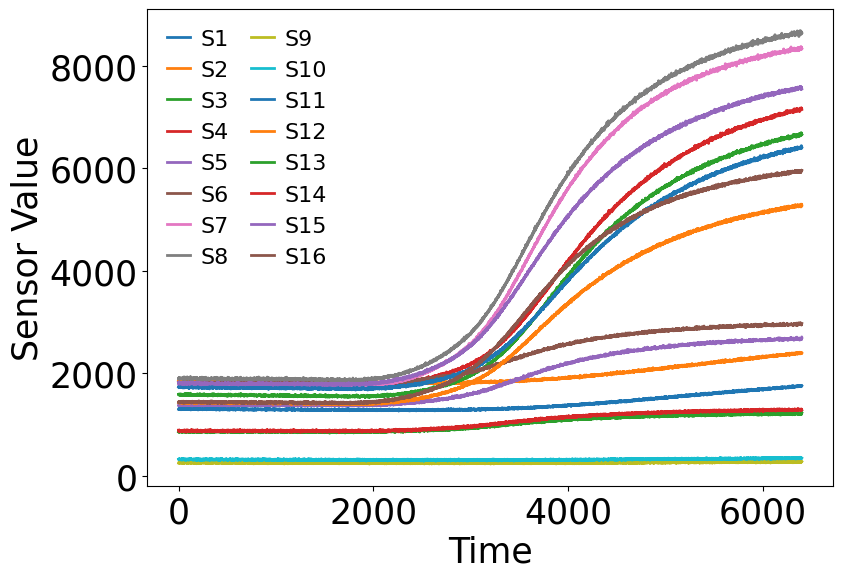

In [10]:
import matplotlib.pyplot as plt

filtered_data = EC3[EC3['Label'] == 8].head(6400)
sensor_columns = [f'Sensor{i}' for i in range(1, 17)]

plt.figure(figsize=(8, 6))

for i, col in enumerate(sensor_columns):
    plt.plot(filtered_data[col].values, label=f'S{i+1}', linewidth=2)

plt.xlabel('Time', fontsize=25)
plt.ylabel('Sensor Value', fontsize=25)

# Đưa legend nằm ngang, bên trong biểu đồ, phía trên
plt.legend(
    ncol=2,
    fontsize=16,
    handlelength=1,
    handletextpad=0.5,
    columnspacing=1.0,
    frameon=False
)

plt.grid(False)
plt.tight_layout(rect=[0, 0, 1, 0.95])  # chừa chỗ cho legend trong khung
plt.tick_params(axis='both', which='major', labelsize=25)

# ✅ Lưu hình ảnh với độ phân giải cao
plt.savefig("high_resolution_figure.png", dpi=600, bbox_inches='tight')  # hoặc dùng .pdf/.tiff tùy nhu cầu

plt.show()

In [11]:
import matplotlib.pyplot as plt

filtered_data = EC4[EC4['Label'] == 245].head(64)
sensor_columns = [f'Sensor{i}' for i in range(1, 17)]

plt.figure(figsize=(8, 6))

for i, col in enumerate(sensor_columns):
    plt.plot(filtered_data[col].values, label=f'S{i+1}', linewidth=2)

plt.xlabel('Time', fontsize=25)
plt.ylabel('Sensor Value', fontsize=25)

# --- Lưới bé và đậm hơn ---
plt.grid(which='major', linewidth=2.0, alpha=0.7)      # lưới chính đậm hơn
plt.grid(which='minor', linewidth=1, linestyle='--', alpha=0.5)  # lưới nhỏ
plt.minorticks_on()   # bật lưới nhỏ (minor grid)

# Legend nằm ngang
plt.legend(
    ncol=2,
    fontsize=16,
    handlelength=1,
    handletextpad=0.5,
    columnspacing=1.0,
    frameon=False
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.tick_params(axis='both', which='major', labelsize=25)

# Lưu hình độ phân giải cao
plt.savefig("high_resolution_figure.png", dpi=600, bbox_inches='tight')

plt.show()

NameError: name 'EC4' is not defined

# Split into 5 splits
- Tách data thành 5 phần nhỏ theo các lần đo (label)
- Chuẩn hóa (Normalization) từng phần bằng Min Max Scaler
- Các phần nhỏ không chứa label nào trùng nhau, có kich cỡ bằng nhau, được tách ngẫu nhiên

In [12]:
import random

numbers = list(range(1, len(EC3['Label'].unique())+1))
random.shuffle(numbers)

# Chia thành 5 list con xấp xỉ bằng nhau
k = 5
chunk_size = len(numbers) // k
remainder = len(numbers) % k

sublists = []
start = 0
for i in range(k):
    end = start + chunk_size + (1 if i < remainder else 0)
    sublists.append(numbers[start:end])
    start = end

# Kiểm tra độ dài từng list con
for i, sublist in enumerate(sublists):
    print(f"---List {i+1} ({len(sublist)} items): {sublist}")

---List 1 (49 items): [222, 118, 132, 75, 111, 119, 89, 36, 87, 195, 221, 68, 231, 21, 131, 77, 244, 145, 10, 185, 98, 158, 210, 147, 239, 213, 234, 27, 110, 64, 236, 61, 19, 182, 144, 220, 32, 33, 125, 34, 242, 205, 186, 209, 163, 188, 102, 35, 41]
---List 2 (49 items): [175, 39, 156, 20, 199, 2, 146, 17, 128, 121, 25, 16, 55, 176, 142, 117, 59, 105, 217, 13, 7, 53, 38, 225, 133, 71, 56, 224, 113, 130, 85, 48, 211, 3, 177, 12, 191, 198, 112, 50, 58, 157, 40, 46, 104, 52, 162, 150, 212]
---List 3 (49 items): [83, 31, 107, 238, 152, 183, 100, 24, 67, 138, 65, 96, 219, 207, 4, 63, 30, 26, 229, 66, 192, 137, 94, 92, 193, 184, 126, 136, 230, 226, 122, 149, 154, 203, 9, 109, 1, 168, 72, 43, 187, 91, 5, 206, 151, 115, 127, 6, 97]
---List 4 (49 items): [228, 18, 216, 160, 237, 88, 190, 14, 165, 194, 164, 141, 178, 78, 174, 180, 124, 95, 108, 106, 240, 171, 202, 62, 86, 93, 80, 243, 37, 49, 235, 42, 116, 173, 227, 155, 167, 70, 81, 60, 197, 51, 69, 245, 23, 8, 82, 232, 208]
---List 5 (49 items

In [13]:
# Tách dataframe thành 5 subdatasets tương ứng và Chuẩn hóa
X_col=[col for col in EC3.columns if 'Sensor' in col]
subdatasets = []
scaler = MinMaxScaler()

for i in range(k):
    subset = EC3[EC3['Label'].isin(sublists[i])].copy().reset_index(drop=True)
    # Normalization - chuẩn hóa trên từng tập subdata/ tập split nhỏ    
    subset[X_col] = pd.DataFrame(scaler.fit_transform(subset[X_col]), columns=X_col)

    subdatasets.append(subset)

# Kiểm tra kết quả
for i, subdf in enumerate(subdatasets):
    print(f"Subdataset {i+1}: {len(subdf)} rows")

Subdataset 1: 529317 rows
Subdataset 2: 614595 rows
Subdataset 3: 562463 rows
Subdataset 4: 549296 rows
Subdataset 5: 587895 rows


In [14]:
subdatasets[4]

,Label,Time (seconds),CO2 conc (ppm),Ethylene conc (ppm),Sensor1,Sensor2,Sensor3,Sensor4,Sensor5,Sensor6,Sensor7,Sensor8,Sensor9,Sensor10,Sensor11,Sensor12,Sensor13,Sensor14,Sensor15,Sensor16
0,11,2400.01,200.0,0.0,0.124324,0.095465,0.113694,0.117317,0.213061,0.230772,0.105880,0.103900,0.016862,0.007951,0.082837,0.087368,0.372512,0.300910,0.082549,0.077579
1,11,2400.02,200.0,0.0,0.125143,0.095611,0.113621,0.116555,0.216414,0.237232,0.106481,0.102898,0.017767,0.023238,0.081527,0.086214,0.349418,0.308072,0.084840,0.078155
2,11,2400.03,200.0,0.0,0.123997,0.095791,0.114735,0.115358,0.204567,0.252350,0.105678,0.103318,0.012705,0.011401,0.084218,0.089102,0.364516,0.300910,0.083446,0.079187
3,11,2400.04,200.0,0.0,0.123508,0.095757,0.114772,0.116119,0.211001,0.253073,0.107150,0.103545,0.011896,0.011401,0.084183,0.089514,0.347646,0.301497,0.084127,0.079686
4,11,2400.05,200.0,0.0,0.126450,0.095510,0.115592,0.115394,0.208298,0.238671,0.105813,0.101608,0.009187,0.013612,0.084080,0.088730,0.348817,0.304189,0.085616,0.078193
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
587890,241,41132.96,0.0,10.0,0.120649,0.002087,0.692712,0.693388,0.511977,0.432150,0.697299,0.704993,0.456340,0.469747,0.717023,0.707251,0.299301,0.434410,0.734754,0.724517
587891,241,41132.97,0.0,10.0,0.118203,0.002205,0.690681,0.691367,0.505392,0.429279,0.703837,0.708684,0.453277,0.458123,0.717864,0.708624,0.314306,0.460507,0.731221,0.723035
587892,241,41132.98,0.0,10.0,0.119672,0.001930,0.692649,0.692251,0.512956,0.432150,0.698161,0.709178,0.456128,0.458569,0.718963,0.708761,0.291952,0.452308,0.734754,0.725798
587893,241,41132.99,0.0,10.0,0.123752,0.002087,0.691443,0.692882,0.517026,0.432600,0.697423,0.709178,0.454753,0.460691,0.717798,0.708487,0.323150,0.457769,0.733870,0.724045


# Augment 
**Thực hiện trên từng phần trong 5 phần:**
- Tăng cường bằng các bước nhảy lệch
- Chuyển sang cỡ ảnh 64x64 rồi lưu
- Mỗi lần đo/ instance/ group/ 1 ảnh gốc, sẽ được tăng cường thành 5 ảnh, lệch nhau step_size dòng

**Ví dụ:** 
- step_size = 10 => sẽ lấy bắt đầu từ index 0, 10, 20, 30, 40
- step_size = 20 => sẽ lấy bắt đầu từ index 0, 20, 40, 60, 80
- step_size = 25 => sẽ lấy bắt đầu từ index 0, 25, 50, 75, 100 (ảnh lấy từ 0 và 100 sẽ gần như trùng nhau)

**Mỗi ảnh sẽ gồm:**
- 64 cột (16 cột cảm biến x4),
- 64 dòng, mỗi dòng có Time(seconds) cách nhau 1 giây, tức cách nhau 100 dòng trong data gốc

In [15]:
# Setup
step_size = 20
X_col=[col for col in EC3.columns if 'Sensor' in col]
y_col=[col for col in EC3.columns if 'conc (ppm)' in col]

In [16]:
%%time
image_data = []

for i, subdata in enumerate(subdatasets):
    folder_name = f'augmented/split{i+1}'
    os.makedirs(folder_name, exist_ok=True)
    grouped_subdata = subdata.groupby('Label')
    
    for label, group in grouped_subdata:
        # Augment by 5 start_index
        for j, start in enumerate(range(0, 5*step_size, step_size)):
            # Get the data in one image
            image = group.iloc[start:(64*100+start):100][X_col]
            img_name = f"img_label{label}_aug{j}.png"

            # Normalize image to range (0, 255), convert to 64x64 size and save img
            image = (image*255).astype(np.uint8)
            image = np.repeat(image, 4, axis = 1)

            # Save the image
            image = Image.fromarray(image).convert("L")
            image.save(f'{folder_name}/{img_name}')

            # Save image information in csv
            row = np.append(group.head(1)[y_col].values[0],[img_name, i+1])
            image_data.append(row)

image_data_df = pd.DataFrame(image_data, columns=np.append(y_col,
                                          ['image_name',
                                          'split_number']))
image_data_df.to_csv('augmented/image_labels.csv', index=False)
image_data_df.groupby('split_number').count()

CPU times: user 3.09 s, sys: 134 ms, total: 3.22 s
Wall time: 3.22 s


,CO2 conc (ppm),Ethylene conc (ppm),image_name
split_number,,,
1,245,245,245
2,245,245,245
3,245,245,245
4,245,245,245
5,245,245,245


# Save unaugment data

In [17]:
%%time
image_data = []

for i, subdata in enumerate(subdatasets):
    folder_name = f'unaugment/split{i+1}'
    os.makedirs(folder_name, exist_ok=True)
    grouped_subdata = subdata.groupby('Label')
    
    for label, group in grouped_subdata:
        # Chỉ lưu MỘT bản của mỗi ảnh
        start = 0
        # Get the data in one image
        image = group.iloc[start:(64*100+start):100][X_col]
        img_name = f"img_label{label}.png"

        # Normalize image to range (0, 255), convert to 64x64 size and save img
        image = (image*255).astype(np.uint8)
        image = np.repeat(image, 4, axis = 1)

        # Save the image
        image = Image.fromarray(image).convert("L")
        image.save(f'{folder_name}/{img_name}')

        # Save image information in csv
        row = np.append(group.head(1)[y_col].values[0],[img_name, i+1])
        image_data.append(row)

image_data_df = pd.DataFrame(image_data, columns=np.append(y_col,
                                          ['image_name',
                                          'split_number']))
image_data_df.to_csv('unaugment/image_labels.csv', index=False)
image_data_df.groupby('split_number').count()

CPU times: user 823 ms, sys: 25.6 ms, total: 848 ms
Wall time: 849 ms


,CO2 conc (ppm),Ethylene conc (ppm),image_name
split_number,,,
1,49,49,49
2,49,49,49
3,49,49,49
4,49,49,49
5,49,49,49


#### Ví dụ đọc data và trường hợp lấy split số 4 làm tập test

In [8]:
# Đọc file csv chứa thông tin về ảnh (nồng độ, tên ảnh, split tương ứng)
folder = "augmented" 
#folder = "unaugment" 
df = pd.read_csv(f"/kaggle/input/data-5/{folder}/image_labels.csv")
df.head()

,CO2 conc (ppm),Ethylene conc (ppm),image_name,split_number
0,0.0,16.67,img_label2_aug0.png,1
1,0.0,16.67,img_label2_aug1.png,1
2,0.0,16.67,img_label2_aug2.png,1
3,0.0,16.67,img_label2_aug3.png,1
4,0.0,16.67,img_label2_aug4.png,1


In [9]:
# Hàm đọc ảnh từ những split cho vào
# Trả về ảnh và nhãn tương ứng dưới dạng: ma trận [số ảnh, 64, 64, 1] và ma trận [số ảnh,2]
def read_img_from_splits(df, split_list):
    # Chỉ lấy các dòng thuộc list split đã chọn
    df_part = df[df['split_number'].isin(split_list)]
    images = []

    # Lặp qua từng hàng trong dataframe để đọc ảnh và lấy nhãn tương ứng 
    for index, row in df_part.iterrows():
        img_path = '/kaggle/input/data-5/'+folder + '/split' + str(row['split_number']) + '/' + str(row['image_name'])
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)  # Đọc ảnh xám
        img = np.array(img).astype('float32') / 255.0  # Chuẩn hóa dữ liệu ảnh
        images.append(img)

    # Chuyển đổi danh sách thành numpy arrays
    images = np.expand_dims(np.array(images), axis=-1)   # Thêm một chiều cho kênh ảnh
    
    return images, df_part[['CO2 conc (ppm)', 'Ethylene conc (ppm)']]

In [10]:
# Xác định tập train và test sẽ gồm những split nào trong 5 split
# Chỉ cần điền những split trong tập test, tập train sẽ tự bao gồm những split còn lại
# VD: split_test = [3,5] thì split_train = [1,2,4]
split_test = [4]

split_train = [i for i in range(1,6) if i not in split_test] 
print("Những split sẽ thuộc tập train là: ", split_train)
print("Những split sẽ thuộc tập test là: ", split_test)

Những split sẽ thuộc tập train là:  [1, 2, 3, 5]
Những split sẽ thuộc tập test là:  [4]


In [11]:
%%time
# Sử dụng hàm đọc ảnh từ thư mục các split tương ứng
X_train, y_train1 = read_img_from_splits(df, split_train)
X_test, y_test1 = read_img_from_splits(df, split_test)
# Khởi tạo và áp dụng MinMaxScaler
scaler = MinMaxScaler()
y_train = scaler.fit_transform(y_train1)
y_test = scaler.fit_transform(y_test1)

print(f'X_train shape: {X_train.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_test shape: {y_test.shape}')

X_train shape: (980, 64, 64, 1)
y_train shape: (980, 2)
X_test shape: (245, 64, 64, 1)
y_test shape: (245, 2)
CPU times: user 786 ms, sys: 357 ms, total: 1.14 s
Wall time: 7.04 s


In [13]:
import pandas as pd
import os
import seaborn as sns
import cv2
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf
from tensorflow.keras import layers, models, Input
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Input, Flatten, Add, Dense, ReLU, Input, Activation 
from tensorflow.keras.layers import Dropout,AveragePooling2D,GlobalAveragePooling2D,BatchNormalization
from tensorflow.keras.regularizers import l2
from keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from sklearn.preprocessing import MinMaxScaler
from sklearn import metrics
from sklearn.metrics import mean_absolute_error, r2_score

2025-12-01 02:24:26.394442: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1764555866.698227      38 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1764555866.811773      38 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [14]:
latent_dim = 256  # Kích thước vector ẩn

# Input
input_img = Input(shape=(64, 64, 1))

# Encoder
x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
x = layers.MaxPooling2D((2, 2), padding='same')(x)
x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2), padding='same')(x)
x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
x = layers.MaxPooling2D((2, 2), padding='same')(x)
x = layers.Flatten()(x)
encoded = layers.Dense(latent_dim, activation='relu')(x)

# Decoder
x = layers.Dense(8 * 8 * 128, activation='relu')(encoded)
x = layers.Reshape((8, 8, 128))(x)
x = layers.Conv2DTranspose(128, (3, 3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2, 2))(x)
x = layers.Conv2DTranspose(64, (3, 3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2, 2))(x)
x = layers.Conv2DTranspose(32, (3, 3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2, 2))(x)
decoded = layers.Conv2DTranspose(1, (3, 3), activation='sigmoid', padding='same')(x)

2025-12-01 02:24:43.098737: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [15]:
# Tạo Autoencoder
autoencoder = models.Model(input_img, decoded)

# Tạo Encoder riêng biệt
encoder = models.Model(input_img, encoded)

# Compile
autoencoder.compile(optimizer='adam', loss='mse')

# Kiểm tra mô hình
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8192)           │     2,105,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 8, 8, 128)      │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 64, 64, 1)      │           289 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,535,553 (17.30 MB)

 Trainable params: 4,535,553 (17.30 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Giả sử có dữ liệu ảnh X_train (64x64x1)
autoencoder.fit(X_train, X_train, epochs=30, batch_size=32, validation_split=0.1)

Epoch 1/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 16s 360ms/step - loss: 0.0581 - val_loss: 0.0369
Epoch 2/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 9s 322ms/step - loss: 0.0263 - val_loss: 0.0170
Epoch 3/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 9s 328ms/step - loss: 0.0131 - val_loss: 0.0061
Epoch 4/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 9s 318ms/step - loss: 0.0044 - val_loss: 0.0042
Epoch 5/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 9s 311ms/step - loss: 0.0022 - val_loss: 0.0031
Epoch 6/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 9s 321ms/step - loss: 0.0015 - val_loss: 0.0025
Epoch 7/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 9s 319ms/step - loss: 0.0011 - val_loss: 0.0025
Epoch 8/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 9s 310ms/step - loss: 9.8198e-04 - val_loss: 0.0024
Epoch 9/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 9s 319ms/step - loss: 7.5472e-04 - val_loss: 0.0022
Epoch 10/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 9s 313ms/step - loss: 7.2793e-04 - val_loss: 0.0025
Epoch 11/30
28/28 ━━━━━━━━━━━━━━━━━━━━ 9s 326ms/step - loss: 8.0592e-04 - val_loss: 0.0021
Epoch 12/30
28/28 ━━━━━━━━━━━━━━━━━

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


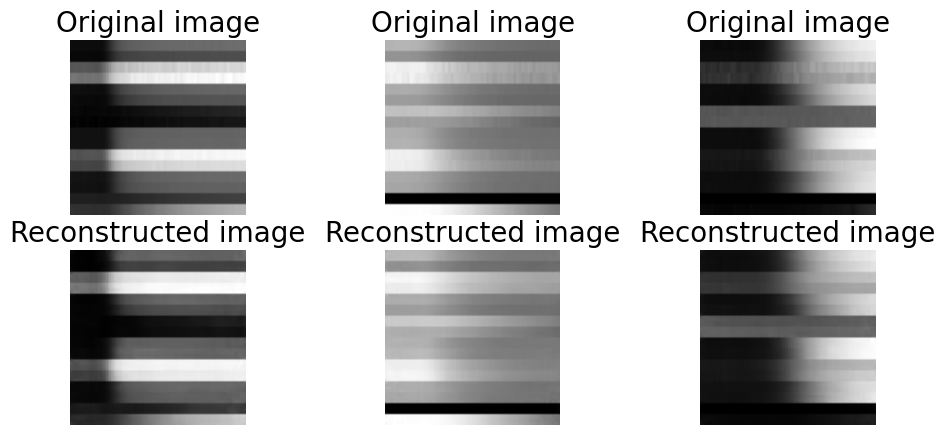

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Chọn các ảnh cách nhau 33 ảnh từ X_test
step = 33
num_images = 3
indices = [i * step for i in range(num_images)]

sample_images = X_test[indices]

# Dự đoán ảnh tái tạo
reconstructed_images = autoencoder.predict(sample_images)

# Vẽ ảnh gốc và ảnh tái tạo
fig, axes = plt.subplots(2, num_images, figsize=(12, 5))

for i in range(num_images):
    # Xoay ảnh 90 độ (Rotate Left)
    orig_rot = np.rot90(sample_images[i].squeeze(), k=1)
    recon_rot = np.rot90(reconstructed_images[i].squeeze(), k=1)

    # Ảnh gốc
    axes[0, i].imshow(orig_rot, cmap='gray')
    axes[0, i].axis('off')
    axes[0, i].set_title("Original image", fontsize=20)

    # Ảnh tái tạo
    axes[1, i].imshow(recon_rot, cmap='gray')
    axes[1, i].axis('off')
    axes[1, i].set_title("Reconstructed image", fontsize=20)

# Điều chỉnh khoảng cách giữa các subplot để gần nhau hơn
plt.subplots_adjust(wspace=0.05, hspace=0.2)

# Lưu ảnh độ phân giải cao
plt.savefig("Fig4_chuyenanh.png", dpi=600, bbox_inches='tight')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 600ms/step


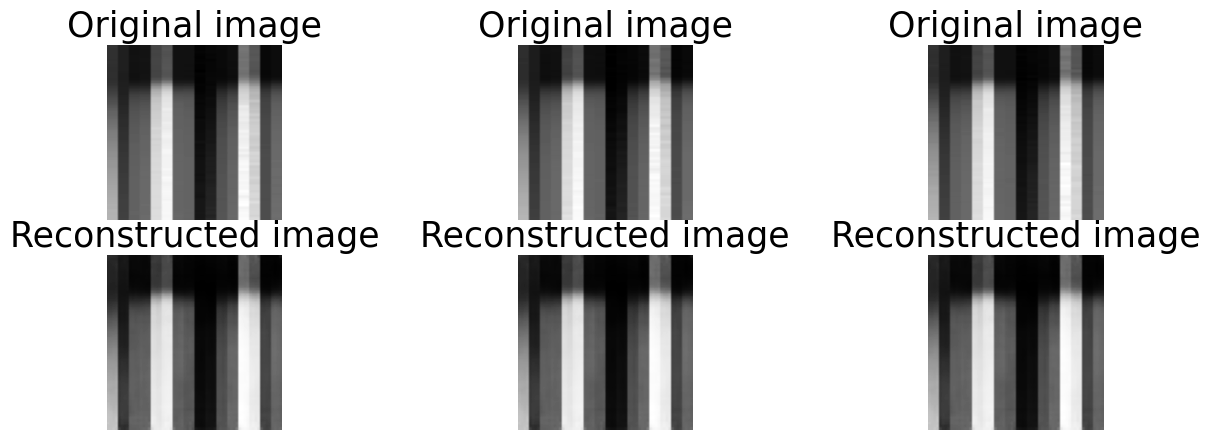

In [13]:
# Chọn một số ảnh từ tập test
num_images = 3
sample_images = X_test[:num_images]

# Dự đoán ảnh tái tạo
reconstructed_images = autoencoder.predict(sample_images)

# Vẽ ảnh gốc và ảnh tái tạo
fig, axes = plt.subplots(2, num_images, figsize=(15, 5))

for i in range(num_images):
    # Ảnh gốc
    axes[0, i].imshow(sample_images[i].squeeze(), cmap='gray')
    axes[0, i].axis('off')
    axes[0, i].set_title("Original image", fontsize=25)

    # Ảnh tái tạo
    axes[1, i].imshow(reconstructed_images[i].squeeze(), cmap='gray')
    axes[1, i].axis('off')
    axes[1, i].set_title("Reconstructed image",fontsize=25)
# ✅ Lưu hình ảnh với độ phân giải cao
plt.savefig("high_resolution_figure1.png", dpi=600, bbox_inches='tight')
plt.show()


In [19]:
from sklearn.metrics import mean_squared_error

num_samples = min(len(X_test), len(reconstructed_images))

mse_scores = [
    mean_squared_error(X_test[i].flatten(), reconstructed_images[i].flatten())
    for i in range(num_samples)
]

print("MSE trung bình:", np.mean(mse_scores))

MSE trung bình: 0.07234932


In [20]:
# Lấy đầu ra của encoder
X_train_encoded = encoder.predict(X_train)  # Dữ liệu ảnh chuyển thành vector đặc trưng
X_test_encoded = encoder.predict(X_test)
# Kiểm tra kích thước đặc trưng đã trích xuất
print(X_train_encoded.shape)  # Dự kiến: (số lượng mẫu, latent_dim)
print(X_test_encoded.shape)
print(y_train.shape)


31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
(980, 256)
(245, 256)
(980, 2)


In [15]:
from sklearn.model_selection import GridSearchCV
from xgboost import XGBRegressor

# Tập hợp các giá trị siêu tham số cần tìm kiếm
param_grid = {
    'n_estimators': [200, 500, 1000],  
    'learning_rate': [0.005, 0.01, 0.02],  
    'max_depth': [3, 4, 5, 6],  
    'subsample': [0.8, 1],  
    'colsample_bytree': [0.7, 1]
}
# Khởi tạo mô hình XGBoost
xgb = XGBRegressor(objective='reg:squarederror', random_state=42)

# Khởi tạo GridSearchCV
grid_search = GridSearchCV(estimator=xgb, param_grid=param_grid, 
                           scoring='neg_mean_squared_error', cv=3, verbose=1, n_jobs=-1)

# Huấn luyện GridSearchCV trên tập train
grid_search.fit(X_train_encoded, y_train)

# In ra bộ tham số tốt nhất
print("Best parameters:", grid_search.best_params_)


Fitting 3 folds for each of 144 candidates, totalling 432 fits
Best parameters: {'colsample_bytree': 0.7, 'learning_rate': 0.02, 'max_depth': 3, 'n_estimators': 1000, 'subsample': 0.8}


In [17]:
from xgboost import XGBRegressor
best_params = {
    'colsample_bytree': 0.7,
    'learning_rate': 0.02,
    'max_depth': 3,
    'n_estimators': 1000,
    'subsample': 0.8
}

# Khởi tạo mô hình với các tham số tối ưu
best_model = XGBRegressor(
    **best_params,                        # ← Giải nén dict thành các đối số
    objective='reg:squarederror',
    random_state=42
)

# Huấn luyện mô hình
best_model.fit(
    X_train_encoded, y_train,
    eval_set=[(X_train_encoded, y_train), (X_test_encoded, y_test)],
    eval_metric=["rmse", "mae"],
    verbose=False,
    early_stopping_rounds=100
)

/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `eval_metric` in `fit` method is deprecated for better compatibility with scikit-learn, use `eval_metric` in constructor or`set_params` instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/xgboost/sklearn.py:889: UserWarning: `early_stopping_rounds` in `fit` method is deprecated for better compatibility with scikit-learn, use `early_stopping_rounds` in constructor or`set_params` instead.
  warnings.warn(


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.7, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.02, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=3, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=1000, n_jobs=None,
             num_parallel_tree=None, random_state=42, ...)

In [18]:
# MLP , XGBOOTS
from sklearn.metrics import mean_squared_error, mean_absolute_error

# best_model = grid_search.best_estimator_

# Dự đoán trên tập test
y_pred = best_model.predict(X_test_encoded)

y_pred_renormalized=scaler.inverse_transform(y_pred)
y_test_renormalized=scaler.inverse_transform(y_test)

In [19]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Output 1
mae_1 = mean_absolute_error(y_test_renormalized[:, 0], y_pred_renormalized[:, 0])
mse_1 = mean_squared_error(y_test_renormalized[:, 0], y_pred_renormalized[:, 0])
rmse_1 = np.sqrt(mse_1)
mean_y1 = np.mean(y_test_renormalized[:, 0])
nrmse_1 = rmse_1 / mean_y1

# Output 2
mae_2 = mean_absolute_error(y_test_renormalized[:, 1], y_pred_renormalized[:, 1])
mse_2 = mean_squared_error(y_test_renormalized[:, 1], y_pred_renormalized[:, 1])
rmse_2 = np.sqrt(mse_2)
mean_y2 = np.mean(y_test_renormalized[:, 1])
nrmse_2 = rmse_2 / mean_y2

# R2 Scores
r2_1 = r2_score(y_test_renormalized[:, 0], y_pred_renormalized[:, 0])
r2_2 = r2_score(y_test_renormalized[:, 1], y_pred_renormalized[:, 1])

# In kết quả
# In kết quả
print(f"Output 1 - MAE: {mae_1:.4f}, MSE: {mse_1:.4f}, RMSE: {rmse_1:.4f}, NRMSE: {nrmse_1*100:.2f}%, R² Score: {r2_1:.4f}")
print(f"Output 2 - MAE: {mae_2:.4f}, MSE: {mse_2:.4f}, RMSE: {rmse_2:.4f}, NRMSE: {nrmse_2*100:.2f}%, R² Score: {r2_2:.4f}")

Output 1 - MAE: 20.6421, MSE: 878.3868, RMSE: 29.6376, NRMSE: 14.56%, R² Score: 0.9726
Output 2 - MAE: 0.8683, MSE: 1.1273, RMSE: 1.0617, NRMSE: 15.15%, R² Score: 0.9640


AE_XGboots
(4)Output 1 - MAE: 21.1777, MSE: 1066.4245, RMSE: 32.6562, NRMSE: 16.04%, R² Score: 0.9667
Output 2 - MAE: 0.9841, MSE: 1.7725, RMSE: 1.3313, NRMSE: 19.00%, R² Score: 0.9434

Output 1 - MAE: 19.5629, MSE: 839.1958, RMSE: 28.9689, NRMSE: 14.23%, R² Score: 0.9738
Output 2 - MAE: 0.9888, MSE: 1.9149, RMSE: 1.3838, NRMSE: 19.75%, R² Score: 0.9388

Output 1 - MAE: 25.2480, MSE: 1129.1550, RMSE: 33.6029, NRMSE: 16.51%, R² Score: 0.9647
Output 2 - MAE: 0.9835, MSE: 1.7560, RMSE: 1.3251, NRMSE: 18.91%, R² Score: 0.9439

(1)Output 1 - MAE: 34.0729, MSE: 3486.5396, RMSE: 59.0469, NRMSE: 37.54%, R² Score: 0.8694
Output 2 - MAE: 1.4433, MSE: 5.1778, RMSE: 2.2755, NRMSE: 30.55%, R² Score: 0.7847

(2)Output 1 - MAE: 22.6842, MSE: 1062.0498, RMSE: 32.5891, NRMSE: 17.48%, R² Score: 0.9459

Output 2 - MAE: 1.0212, MSE: 1.8942, RMSE: 1.3763, NRMSE: 16.72%, R² Score: 0.9305

================================tăng cường
4
Output 1 - MAE: 18.5040, MSE: 902.7207, RMSE: 30.0453, NRMSE: 14.76%, R² Score: 0.9718
Output 2 - MAE: 0.7839, MSE: 1.0000, RMSE: 1.0000, NRMSE: 14.27%, R² Score: 0.9680
Output 1 - MAE: 21.0240, MSE: 951.7038, RMSE: 30.8497, NRMSE: 15.16%, R² Score: 0.9703
Output 2 - MAE: 1.0850, MSE: 2.5574, RMSE: 1.5992, NRMSE: 22.82%, R² Score: 0.9183

Output 1 - MAE: 21.2180, MSE: 830.2067, RMSE: 28.8133, NRMSE: 14.16%, R² Score: 0.9741
Output 2 - MAE: 1.0030, MSE: 1.7759, RMSE: 1.3326, NRMSE: 19.02%, R² Score: 0.9432
Output 1 - MAE: 20.9937, MSE: 1251.5327, RMSE: 35.3770, NRMSE: 17.38%, R² Score: 0.9609
Output 2 - MAE: 0.8086, MSE: 1.2466, RMSE: 1.1165, NRMSE: 15.93%, R² Score: 0.9602
Output 1 - MAE: 18.2194, MSE: 736.5699, RMSE: 27.1398, NRMSE: 13.33%, R² Score: 0.9770
Output 2 - MAE: 0.9929, MSE: 1.8687, RMSE: 1.3670, NRMSE: 19.51%, R² Score: 0.9403

2
Output 1 - MAE: 23.6542, MSE: 1468.0260, RMSE: 38.3148, NRMSE: 18.82%, R² Score: 0.9542
Output 2 - MAE: 1.0034, MSE: 2.1896, RMSE: 1.4797, NRMSE: 21.12%, R² Score: 0.9300
Output 1 - MAE: 18.7430, MSE: 709.4293, RMSE: 26.6351, NRMSE: 13.09%, R² Score: 0.9778
Output 2 - MAE: 0.8176, MSE: 1.3508, RMSE: 1.1622, NRMSE: 16.59%, R² Score: 0.9568
Output 1 - MAE: 31.8983, MSE: 3163.5745, RMSE: 56.2457, NRMSE: 27.63%, R² Score: 0.9012
Output 2 - MAE: 1.0029, MSE: 1.9347, RMSE: 1.3910, NRMSE: 19.85%, R² Score: 0.9382
1
Output 1 - MAE: 24.3380, MSE: 1808.5690, RMSE: 42.5273, NRMSE: 27.04%, R² Score: 0.9323
Output 2 - MAE: 1.4210, MSE: 4.9803, RMSE: 2.2317, NRMSE: 29.96%, R² Score: 0.7930
Output 1 - MAE: 43.3590, MSE: 4731.2707, RMSE: 68.7842, NRMSE: 43.73%, R² Score: 0.8228
Output 2 - MAE: 1.5127, MSE: 5.2437, RMSE: 2.2899, NRMSE: 30.74%, R² Score: 0.7820

3
Output 1 - MAE: 23.3227, MSE: 1754.4613, RMSE: 41.8863, NRMSE: 20.12%, R² Score: 0.9312
Output 2 - MAE: 1.2286, MSE: 2.1026, RMSE: 1.4500, NRMSE: 17.91%, R² Score: 0.9149
5
Output 1 - MAE: 23.9632, MSE: 1672.9248, RMSE: 40.9014, NRMSE: 23.05%, R² Score: 0.9422
Output 2 - MAE: 1.3220, MSE: 4.4796, RMSE: 2.1165, NRMSE: 27.53%, R² Score: 0.8613

=================tăng train 4 ===============
AE_MLP
Output 1 - MAE: 43.0881, MSE: 2456.8189, RMSE: 49.5663, NRMSE: 24.35%, R² Score: 0.9233
Output 2 - MAE: 1.3862, MSE: 2.7839, RMSE: 1.6685, NRMSE: 23.81%, R² Score: 0.9110

AE+LSTM
4
Output 1 - MAE: 22.7651, MSE: 842.9005, RMSE: 29.0327, NRMSE: 14.26%, R² Score: 0.9737
Output 2 - MAE: 0.6137, MSE: 0.5651, RMSE: 0.7517, NRMSE: 10.73%, R² Score: 0.9819

Output 1 - MAE: 19.4161, MSE: 554.8154, RMSE: 23.5545, NRMSE: 11.57%, R² Score: 0.9827
Output 2 - MAE: 0.6135, MSE: 0.7799, RMSE: 0.8831, NRMSE: 12.60%, R² Score: 0.9751

Output 1 - MAE: 23.8067, MSE: 708.8594, RMSE: 26.6244, NRMSE: 13.08%, R² Score: 0.9779
Output 2 - MAE: 0.7071, MSE: 0.7895, RMSE: 0.8885, NRMSE: 12.68%, R² Score: 0.9748
(1)
Output 1 - MAE: 29.4270, MSE: 1336.1645, RMSE: 36.5536, NRMSE: 23.24%, R² Score: 0.9499
Output 2 - MAE: 0.9133, MSE: 2.7994, RMSE: 1.6731, NRMSE: 22.46%, R² Score: 0.8836



In [21]:
import shutil

# Nén toàn bộ thư mục /kaggle/working thành file working.zip
shutil.make_archive('/kaggle/working/working', 'zip', '/kaggle/working')

'/kaggle/working/working.zip'

In [43]:
import matplotlib.pyplot as plt
import numpy as np

def plot_groundtruth_vs_prediction(y_true, y_pred, gas_name="Gas Concentration"):
    # Lấy 101 phần tử đầu tiên
    y_true = y_true[:245]
    y_pred = y_pred[:245]
    x = np.arange(245)

    # Tính độ lệch
    delta = y_pred - y_true

    # Tăng DPI khi hiển thị
    plt.figure(figsize=(10, 5), dpi=150)

    # Vẽ Groundtruth
    plt.plot(x, y_true, label=f"Groundtruth {gas_name}", color='blue', linewidth=2.5)

    # Vẽ Prediction
    plt.plot(x, y_pred, label=f"Prediction {gas_name}", color='red', linestyle='--', linewidth=2.5)

    # Vẽ độ lệch Δ
    plt.plot(x, delta, label="Δ (Prediction - Groundtruth)", color='green', linewidth=3)

    # Nhãn và định dạng
    plt.xlabel("Sample Index", fontsize=18)
    plt.ylabel("Concentration (ppm)", fontsize=18)
    plt.legend(fontsize=16)
    plt.tick_params(axis='both', which='major', labelsize=16)

    # ✅ Lưới đậm hơn
    plt.grid(True, linestyle='--', linewidth=2.0, alpha=0.7)

    # Bố cục và lưu file độ phân giải cao
    plt.tight_layout()
    plt.savefig("prediction_Ethy_chuan.png", dpi=600, bbox_inches='tight')
    plt.show()

In [27]:
import matplotlib.pyplot as plt
import numpy as np

def plot_groundtruth_vs_prediction(y_true, y_pred, gas_name="Nồng độ khí"):
    # Lấy 101 phần tử đầu tiên
    y_true = y_true[:245]
    y_pred = y_pred[:245]
    x = np.arange(245)

    # Tính độ lệch
    delta = y_pred - y_true

    # Tăng DPI khi hiển thị
    plt.figure(figsize=(10, 5), dpi=150)

    # Vẽ Groundtruth
    plt.plot(x, y_true, label=f"Giá trị thực {gas_name}", color='blue', linewidth=2.5)

    # Vẽ Prediction
    plt.plot(x, y_pred, label=f"Giá trị dự đoán {gas_name}", color='red', linestyle='--', linewidth=2.5)

    # Vẽ độ lệch Δ
    plt.plot(x, delta, label="Δ (Dự đoán - Thực)", color='green', linewidth=3)

    # Nhãn và định dạng
    plt.xlabel("Chỉ số mẫu", fontsize=18)
    plt.ylabel("Nồng độ", fontsize=18)
    plt.legend(fontsize=16)
    plt.tick_params(axis='both', which='major', labelsize=16)
    #plt.grid(True, linestyle='--', alpha=0.5)
    # ✅ Thêm lưới
    plt.grid(True, linestyle='--', alpha=0.5)
    # Bố cục và lưu file độ phân giải cao
    plt.tight_layout()
    plt.savefig("prediction_vs_groundtruth_CO.png", dpi=600)
    plt.show()

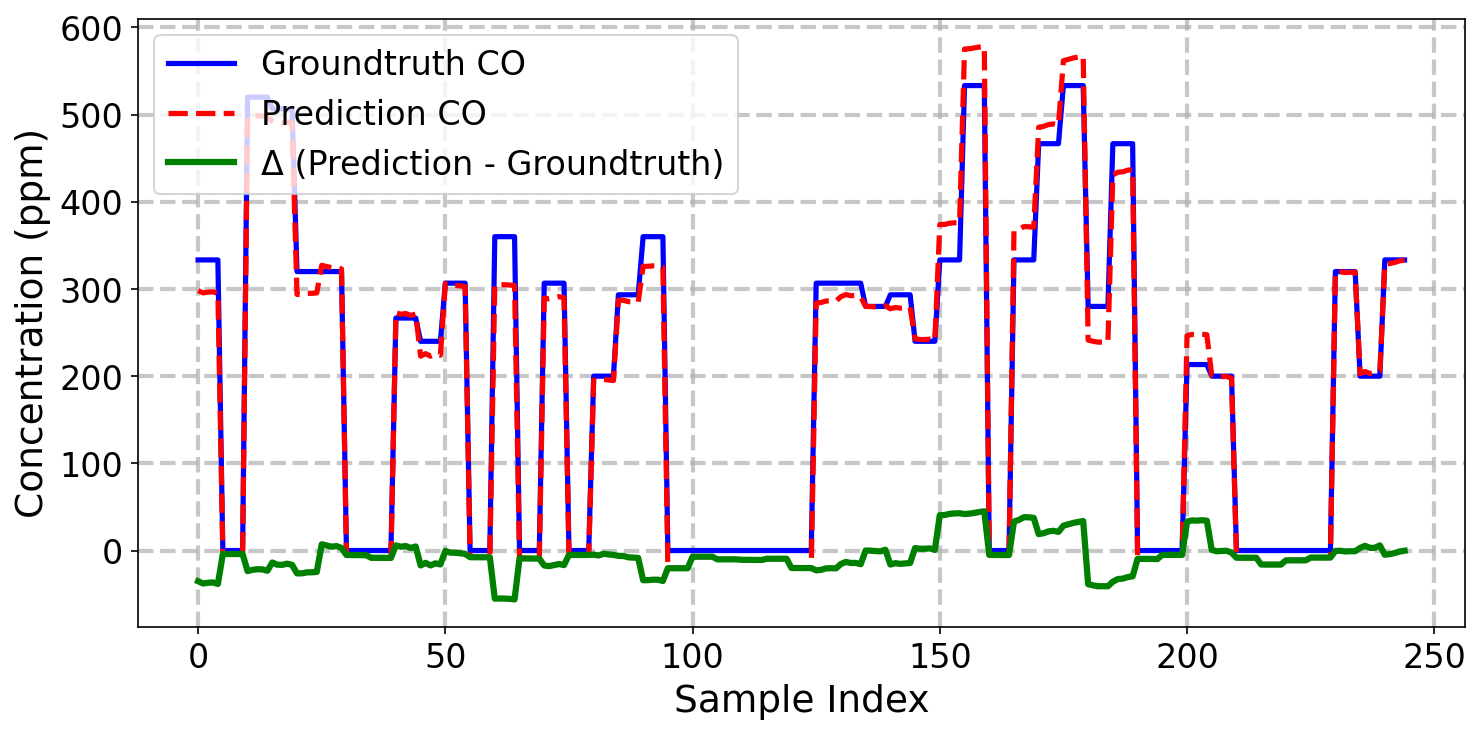

In [29]:
# Ví dụ cho việc vẽ lại biểu đồ sau khi inverse transform
plot_groundtruth_vs_prediction(y_test_renormalized[:, 0], y_pred_renormalized[:, 0], gas_name="CO")

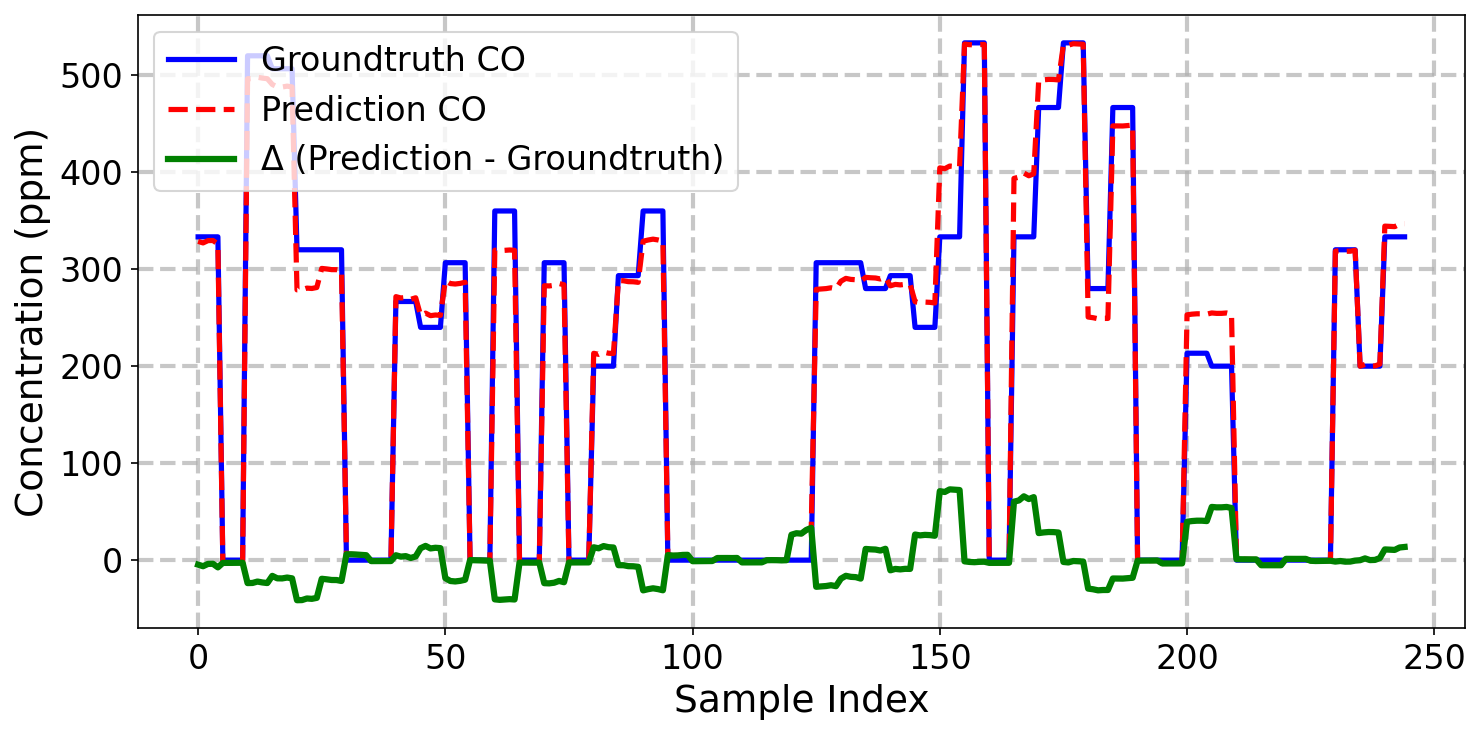

In [33]:
# Ví dụ cho việc vẽ lại biểu đồ sau khi inverse transform
plot_groundtruth_vs_prediction(y_test_renormalized[:, 0], y_pred_renormalized[:, 0], gas_name="CO")


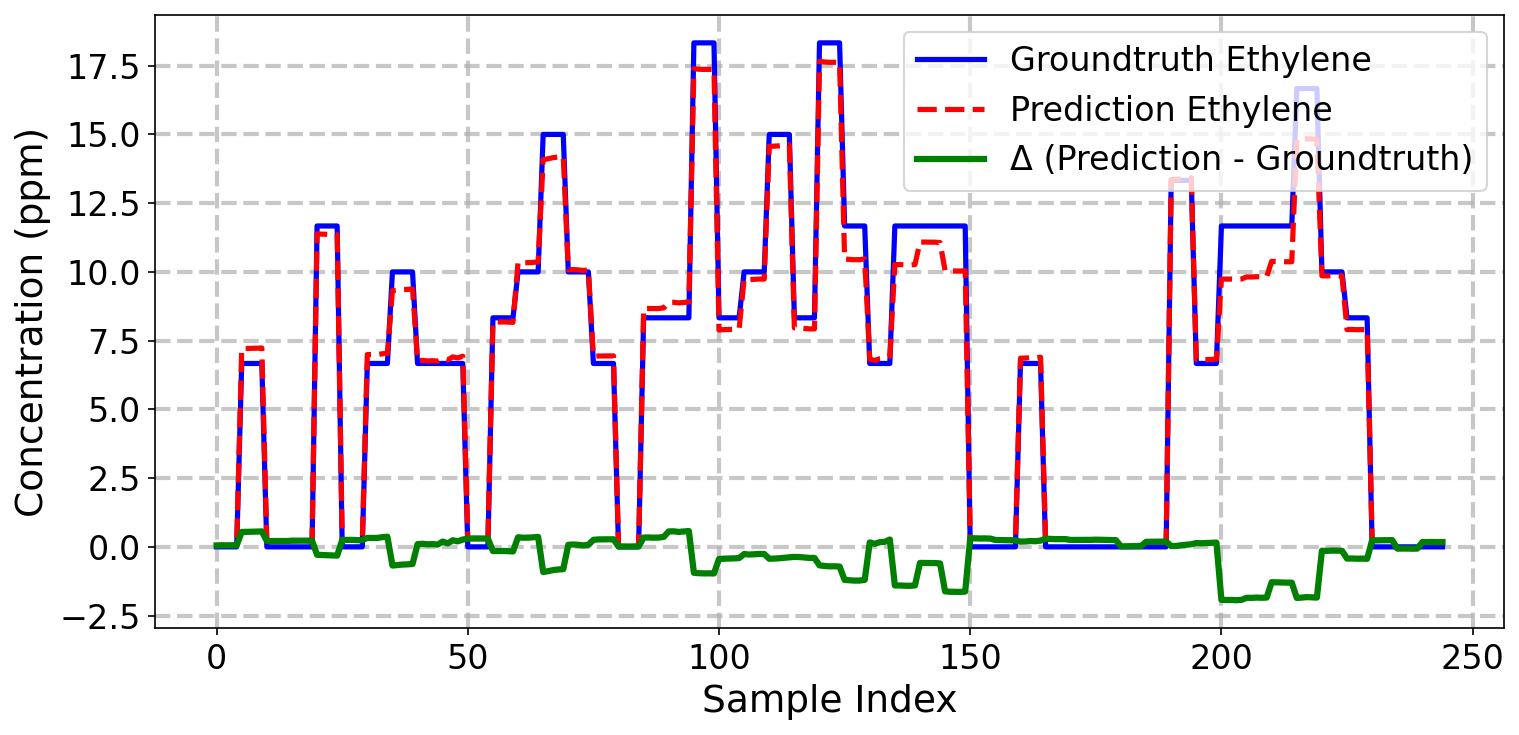

In [44]:
plot_groundtruth_vs_prediction(y_test_renormalized[:, 1], y_pred_renormalized[:, 1], gas_name="Ethylene")

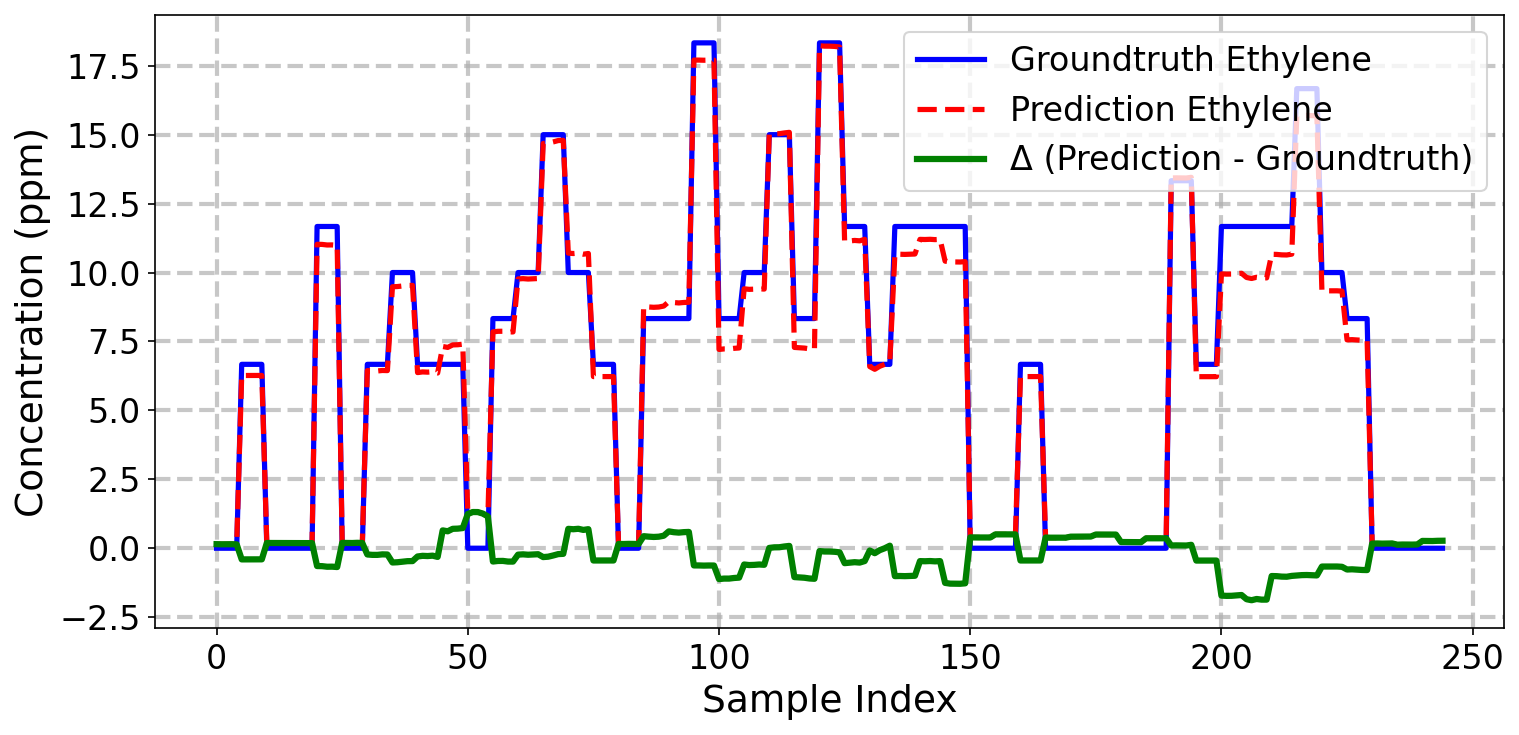

In [34]:
plot_groundtruth_vs_prediction(y_test_renormalized[:, 1], y_pred_renormalized[:, 1], gas_name="Ethylene")

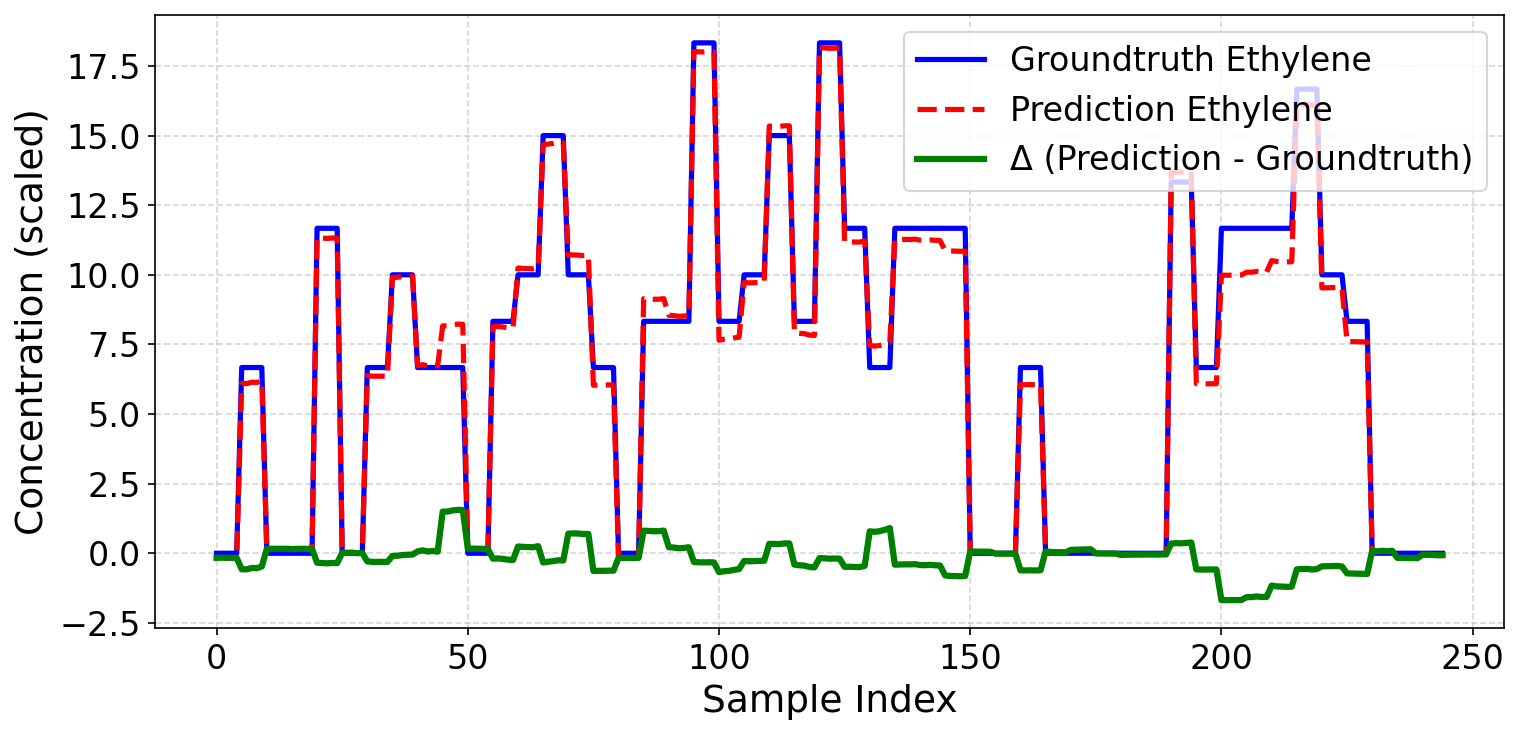

In [19]:
plot_groundtruth_vs_prediction(y_test_renormalized[:, 1], y_pred_renormalized[:, 1], gas_name="Ethylene")

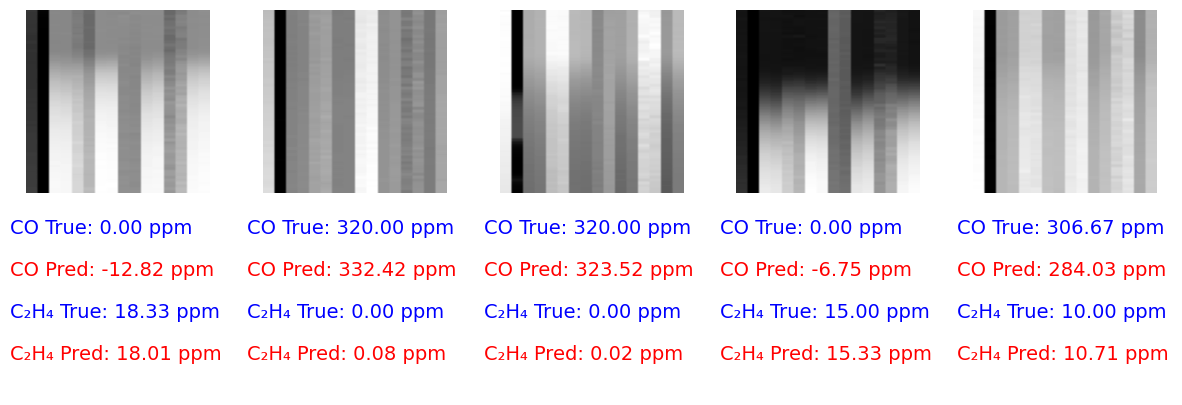

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# Chọn 5 mẫu ngẫu nhiên từ tập kiểm tra
num_samples = 5
random_indices = np.random.choice(X_test.shape[0], num_samples, replace=False)

plt.figure(figsize=(15, 5))  # Giảm chiều cao figure

for i, idx in enumerate(random_indices):
    img = X_test[idx].reshape(64, 64)
    true_co2 = y_test_renormalized[idx, 0]
    true_ethylene = y_test_renormalized[idx, 1]
    pred_co2 = y_pred_renormalized[idx, 0]
    pred_ethylene = y_pred_renormalized[idx, 1]

    # Hiển thị ảnh
    plt.subplot(2, 5, i + 1)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    #plt.title(f"Sample {idx+1}", fontsize=11)

    # Hiển thị thông tin khí
    plt.subplot(2, 5, i + 6)
    plt.axis('off')
    plt.text(0.0, 0.88, f"CO True: {true_co2:.2f} ppm", color="blue", fontsize=14)
    plt.text(0.0, 0.65, f"CO Pred: {pred_co2:.2f} ppm", color="red", fontsize=14)
    plt.text(0.0, 0.42, f"C₂H₄ True: {true_ethylene:.2f} ppm", color="blue", fontsize=14)
    plt.text(0.0, 0.19, f"C₂H₄ Pred: {pred_ethylene:.2f} ppm", color="red", fontsize=14)

# Tinh chỉnh layout: giảm khoảng cách giữa các hàng và cột
plt.subplots_adjust(wspace=0.1, hspace=0.1)
plt.savefig("True_pred.png", dpi=600, bbox_inches='tight')
plt.show()

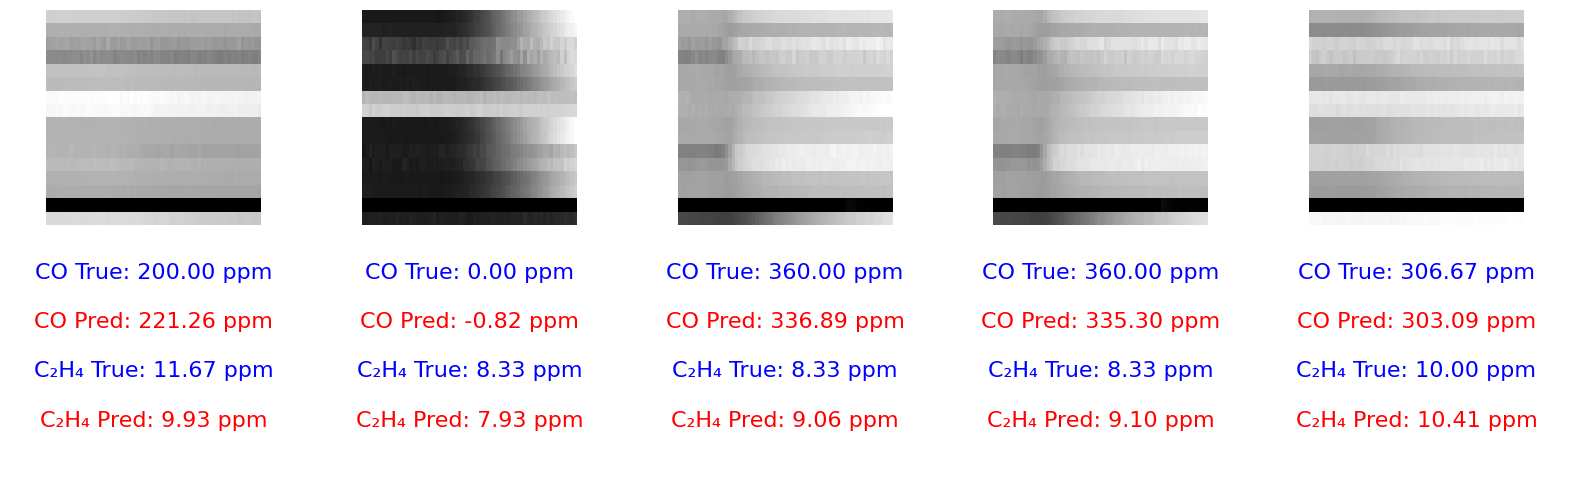

In [30]:
import matplotlib.pyplot as plt
import numpy as np

# Chọn 5 mẫu ngẫu nhiên từ tập kiểm tra
num_samples = 5
random_indices = np.random.choice(X_test.shape[0], num_samples, replace=False)

plt.figure(figsize=(20, 6))  # chỉnh lại chút để cân đối

for i, idx in enumerate(random_indices):
    img = X_test[idx].reshape(64, 64)

    # Xoay ảnh 90 độ (Rotate Left)
    img_rotated = np.rot90(img, k=1)

    true_co = y_test_renormalized[idx, 0]
    true_ethylene = y_test_renormalized[idx, 1]
    pred_co = y_pred_renormalized[idx, 0]
    pred_ethylene = y_pred_renormalized[idx, 1]

    # --- HÀNG 1: ẢNH ---
    plt.subplot(2, 5, i + 1)
    plt.imshow(img_rotated, cmap='gray')
    plt.axis('off')

    # --- HÀNG 2: TEXT, căn giữa ---
    plt.subplot(2, 5, i + 6)
    plt.axis('off')

    plt.text(
        0.5, 0.90, f"CO True: {true_co:.2f} ppm", 
        color="blue", fontsize=16, ha='center'
    )
    plt.text(
        0.5, 0.67, f"CO Pred: {pred_co:.2f} ppm", 
        color="red", fontsize=16, ha='center'
    )
    plt.text(
        0.5, 0.44, f"C₂H₄ True: {true_ethylene:.2f} ppm", 
        color="blue", fontsize=16, ha='center'
    )
    plt.text(
        0.5, 0.21, f"C₂H₄ Pred: {pred_ethylene:.2f} ppm", 
        color="red", fontsize=16, ha='center'
    )

# Giảm khoảng cách giữa các subplot
plt.subplots_adjust(wspace=0.1, hspace=0.15)

# Lưu ảnh nếu muốn
plt.savefig("Fig10_True_pred.png", dpi=600, bbox_inches='tight')

plt.show()

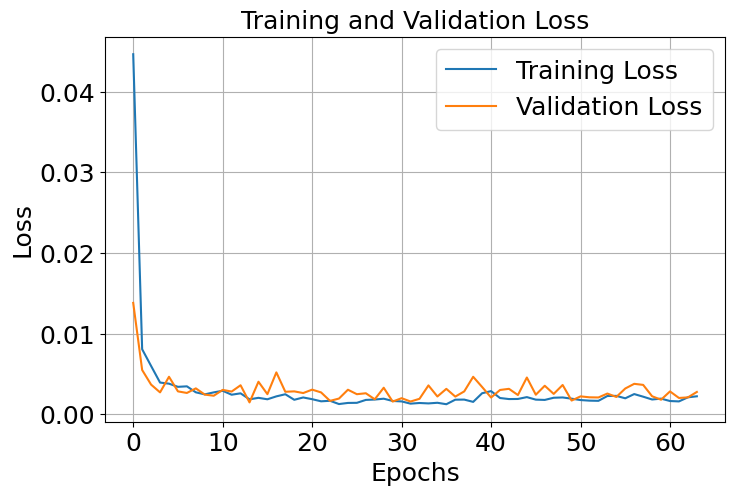

In [33]:
# CHUAN LOSS với font size 18
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs', fontsize=18)
plt.ylabel('Loss', fontsize=18)
plt.title('Training and Validation Loss', fontsize=18)
plt.legend(fontsize=18)
plt.grid(True)

# Tăng font của các chỉ số trục
plt.tick_params(axis='both', which='major', labelsize=18)
plt.savefig("Loss.png", dpi=600, bbox_inches='tight')
plt.show()

In [159]:
# XGBoot
results = best_model.evals_result()

# 🎨 Vẽ RMSE
plt.figure(figsize=(8, 5))
plt.plot(results['validation_0']['rmse'], label='Training RMSE')
plt.plot(results['validation_1']['rmse'], label='Validation RMSE')

# Thêm nhãn và legend với font lớn
plt.xlabel("Epochs", fontsize=18)
plt.ylabel("RMSE", fontsize=18)
#plt.title("RMSE Learning Curve", fontsize=18)
plt.legend(fontsize=18)

# Tăng kích thước chữ số trên trục
plt.tick_params(axis='both', which='major', labelsize=18)

# Căn chỉnh bố cục và lưu ảnh
plt.tight_layout()
plt.savefig("reconstruction_highres.png", dpi=600)
plt.show()

AttributeError: 'Sequential' object has no attribute 'evals_result'

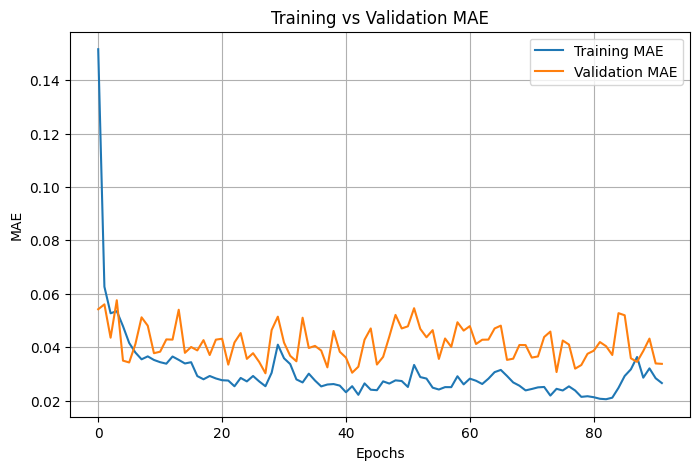

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.title('Training vs Validation MAE')
plt.legend()
plt.grid(True)
plt.show()

In [163]:
# 🎨 Vẽ MAE # XGBoot
plt.figure(figsize=(8, 5))
plt.plot(results['validation_0']['mae'], label='Training MAE')
plt.plot(results['validation_1']['mae'], label='Validation MAE')

# Tăng kích thước chữ
plt.xlabel("Epochs", fontsize=18)
plt.ylabel("MAE", fontsize=18)
#plt.title("MAE Learning Curve", fontsize=18)
plt.legend(fontsize=18)
plt.tick_params(axis='both', which='major', labelsize=18)

# Căn chỉnh bố cục và lưu ảnh chất lượng cao
plt.tight_layout()
plt.savefig("reconstruction_highres.png", dpi=600)
plt.show()


NameError: name 'results' is not defined

<Figure size 800x500 with 0 Axes>

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


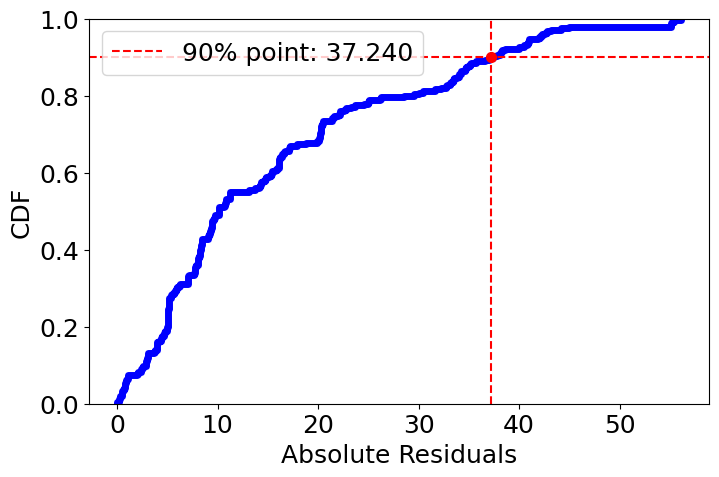

In [47]:
# Compute absolute residuals
abs_residuals_gas1 = np.abs(y_test_renormalized[:, 0] - y_pred_renormalized[:, 0])
abs_residuals_gas2 = np.abs(y_test_renormalized[:, 1] - y_pred_renormalized[:, 1])

# Compute 90th percentile values
x90_gas1 = np.percentile(abs_residuals_gas1, 90)
### 🎨 Plot CDF cho Gas 1 (CO)
plt.figure(figsize=(8, 5))
sns.ecdfplot(abs_residuals_gas1, color='blue', linewidth=5)
plt.axvline(x=x90_gas1, color='red', linestyle='--', label=f"90% point: {x90_gas1:.3f}")
plt.axhline(y=0.9, color='red', linestyle='--')
plt.scatter([x90_gas1], [0.9], color='red', s=50, zorder=10)
#plt.title("CDF of Absolute Residuals for CO", fontsize=16)
plt.xlabel("Absolute Residuals", fontsize=18)
plt.ylabel("CDF", fontsize=18)
plt.legend(fontsize=18)
plt.tick_params(axis='both', labelsize=18)
plt.savefig("CDF_CO_chuan_L6.png", dpi=600, bbox_inches='tight')

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


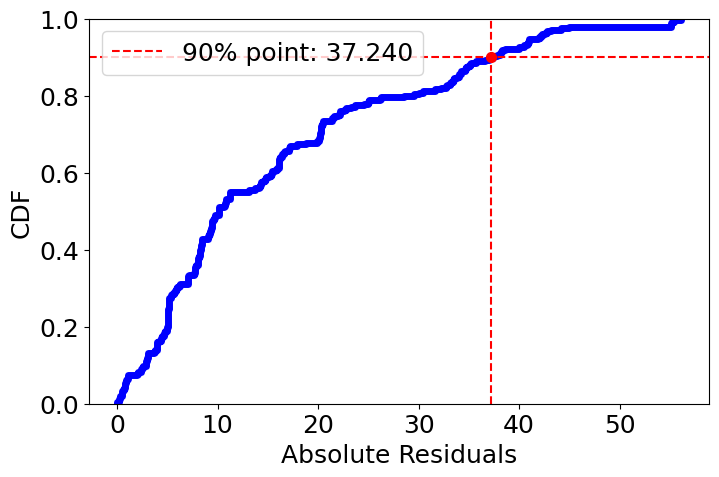

In [34]:
# Compute absolute residuals
abs_residuals_gas1 = np.abs(y_test_renormalized[:, 0] - y_pred_renormalized[:, 0])
abs_residuals_gas2 = np.abs(y_test_renormalized[:, 1] - y_pred_renormalized[:, 1])

# Compute 90th percentile values
x90_gas1 = np.percentile(abs_residuals_gas1, 90)
### 🎨 Plot CDF cho Gas 1 (CO)
plt.figure(figsize=(8, 5))
sns.ecdfplot(abs_residuals_gas1, color='blue', linewidth=5)
plt.axvline(x=x90_gas1, color='red', linestyle='--', label=f"90% point: {x90_gas1:.3f}")
plt.axhline(y=0.9, color='red', linestyle='--')
plt.scatter([x90_gas1], [0.9], color='red', s=50, zorder=10)
#plt.title("CDF of Absolute Residuals for CO", fontsize=16)
plt.xlabel("Absolute Residuals", fontsize=18)
plt.ylabel("CDF", fontsize=18)
plt.legend(fontsize=18)
plt.tick_params(axis='both', labelsize=18)
plt.savefig("CDF_CO_chuan.png", dpi=600, bbox_inches='tight')

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


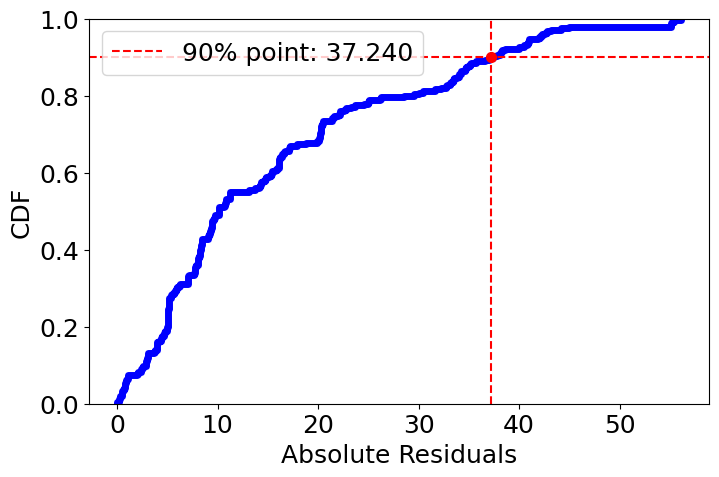

In [35]:
# Compute absolute residuals
abs_residuals_gas1 = np.abs(y_test_renormalized[:, 0] - y_pred_renormalized[:, 0])
abs_residuals_gas2 = np.abs(y_test_renormalized[:, 1] - y_pred_renormalized[:, 1])

# Compute 90th percentile values
x90_gas1 = np.percentile(abs_residuals_gas1, 90)
### 🎨 Plot CDF cho Gas 1 (CO)
plt.figure(figsize=(8, 5))
sns.ecdfplot(abs_residuals_gas1, color='blue', linewidth=5)
plt.axvline(x=x90_gas1, color='red', linestyle='--', label=f"90% point: {x90_gas1:.3f}")
plt.axhline(y=0.9, color='red', linestyle='--')
plt.scatter([x90_gas1], [0.9], color='red', s=50, zorder=10)
#plt.title("CDF of Absolute Residuals for CO", fontsize=16)
plt.xlabel("Absolute Residuals", fontsize=18)
plt.ylabel("CDF", fontsize=18)
plt.legend(fontsize=18)
plt.tick_params(axis='both', labelsize=18)
plt.savefig("CDF_CO_2.png", dpi=600)

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


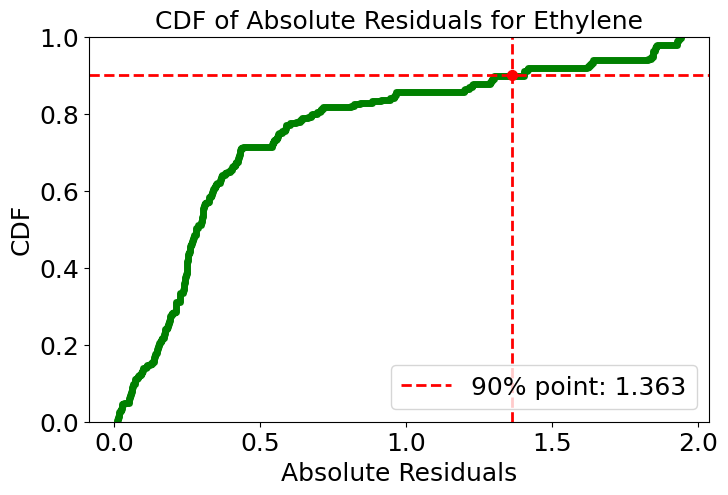

In [39]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Tính 90% quantile
x90_gas2 = np.quantile(abs_residuals_gas2, 0.9)

### 🎨 Plot CDF cho Gas 2 (Ethylene)
plt.figure(figsize=(8, 5))
sns.ecdfplot(abs_residuals_gas2, color='green', linewidth=5)

# Vẽ đường ngang & dọc 90%
plt.axvline(x=x90_gas2, color='red', linestyle='--', label=f"90% point: {x90_gas2:.3f}", linewidth=2)
plt.axhline(y=0.9, color='red', linestyle='--', linewidth=2)

# Đánh dấu điểm 90%
plt.scatter([x90_gas2], [0.9], color='red', s=50, zorder=18)

# Title và labels
plt.title("CDF of Absolute Residuals for Ethylene", fontsize=18)
plt.xlabel("Absolute Residuals", fontsize=18)
plt.ylabel("CDF", fontsize=18)

# Legend với font size 18
plt.legend(fontsize=18)

# Tick labels font size 18
plt.tick_params(axis='both', labelsize=18)

# Lưu hình nếu muốn
plt.savefig("Ethy1.png", dpi=600, bbox_inches='tight')

plt.show()

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


<function matplotlib.pyplot.show(close=None, block=None)>

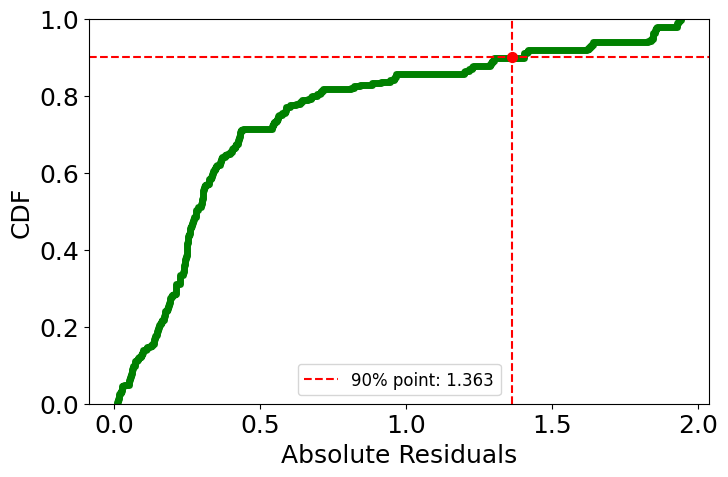

In [36]:
x90_gas2 = np.quantile(abs_residuals_gas2, 0.9)
### 🎨 Plot CDF cho Gas 2 (Ethylene)
plt.figure(figsize=(8, 5))
sns.ecdfplot(abs_residuals_gas2, color='green', linewidth=5)
plt.axvline(x=x90_gas2, color='red', linestyle='--', label=f"90% point: {x90_gas2:.3f}")
plt.axhline(y=0.9, color='red', linestyle='--')
plt.scatter([x90_gas2], [0.9], color='red', s=50, zorder=18)
#plt.title("CDF of Absolute Residuals for Ethylene", fontsize=18)
plt.xlabel("Absolute Residuals", fontsize=18)
plt.ylabel("CDF", fontsize=18)
plt.legend(fontsize=12)
plt.tick_params(axis='both', labelsize=18)
#plt.savefig("reconstruction_highres.png", dpi=600)
plt.show

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


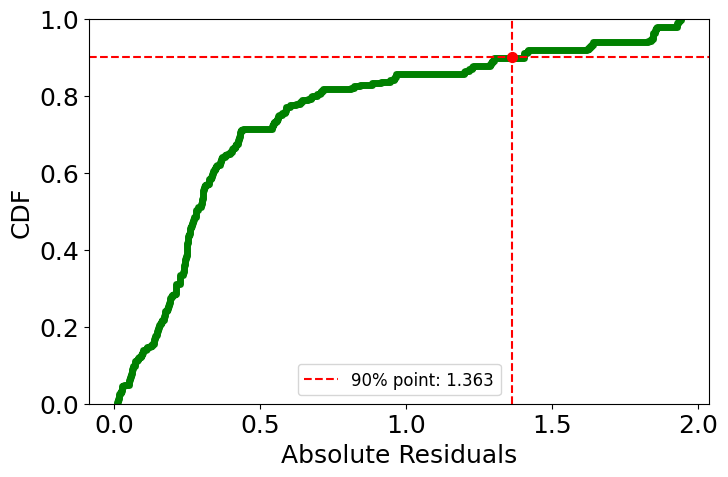

In [37]:
x90_gas2 = np.quantile(abs_residuals_gas2, 0.9)
### 🎨 Plot CDF cho Gas 2 (Ethylene)
plt.figure(figsize=(8, 5))
sns.ecdfplot(abs_residuals_gas2, color='green', linewidth=5)
plt.axvline(x=x90_gas2, color='red', linestyle='--', label=f"90% point: {x90_gas2:.3f}")
plt.axhline(y=0.9, color='red', linestyle='--')
plt.scatter([x90_gas2], [0.9], color='red', s=50, zorder=18)
#plt.title("CDF of Absolute Residuals for Ethylene", fontsize=18)
plt.xlabel("Absolute Residuals", fontsize=18)
plt.ylabel("CDF", fontsize=18)
plt.legend(fontsize=12)
plt.tick_params(axis='both', labelsize=18)
plt.savefig("reconstruction_highres.png", dpi=600)

In [1]:
#=======================MLP===============
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Khởi tạo mô hình MLP
best_model = Sequential()
best_model.add(Dense(128, activation='relu', input_shape=(X_train_encoded.shape[1],)))
best_model.add(Dropout(0.3))  # tương đương subsample/colsample_bytree để tránh overfitting
best_model.add(Dense(64, activation='relu'))
best_model.add(Dropout(0.3))
best_model.add(Dense(2))  # Sửa thành 2 neurons để dự đoán 2 biến đầu ra

# Compile mô hình
best_model.compile(
    optimizer=Adam(learning_rate=0.02),  # dùng learning_rate từ best_params
    loss='mse',
    metrics=['mae']
)

# Early stopping tương đương với n_estimators
early_stop = EarlyStopping(monitor='val_loss', patience=50, restore_best_weights=True)

# Huấn luyện mô hình
history = best_model.fit(
    X_train_encoded, y_train,
    validation_data=(X_test_encoded, y_test),
    epochs=1000,         # tương đương n_estimators
    batch_size=32,
    verbose=1,
    callbacks=[early_stop]
)

2025-09-02 11:36:22.892575: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1756812983.168242      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1756812983.246735      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


NameError: name 'X_train_encoded' is not defined

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Reshape dữ liệu thành (samples, timesteps, features)
X_test_lstm = X_test_encoded.reshape((X_test_encoded.shape[0], 16, 16))
X_train_lstm = X_train_encoded.reshape((X_train_encoded.shape[0], 16, 16))

# Xây dựng mô hình LSTM 1 lớp
model = Sequential()
model.add(LSTM(128, activation='tanh', input_shape=(16, 16)))  # chỉ 1 lớp LSTM
model.add(Dropout(0.2))
model.add(Dense(32, activation='relu'))
model.add(Dense(2))  # dự đoán NH₃ và H₂S

# Compile
model.compile(optimizer=Adam(learning_rate=0.002), loss='mse', metrics=['mae'])

# Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=50, restore_best_weights=True)

# Huấn luyện
history = model.fit(
    X_train_lstm, y_train,
    validation_data=(X_test_lstm, y_test),
    epochs=1000,
    batch_size=32,
    verbose=1,
    callbacks=[early_stop]
)

LSTM theo STEP 16

In [64]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

X_test_lstm = X_test_encoded.reshape((X_test_encoded.shape[0], 16, 16))
X_train_lstm = X_train_encoded.reshape((X_train_encoded.shape[0], 16, 16))

model = Sequential()
model.add(LSTM(128, activation='tanh', return_sequences=True, input_shape=(16, 16)))
model.add(Dropout(0.2))
model.add(LSTM(64, activation='tanh', return_sequences=False))
model.add(Dropout(0.2))
model.add(Dense(32, activation='relu'))
model.add(Dense(2))  # Ví dụ dự đoán NH₃ và H₂S

model.compile(optimizer=Adam(learning_rate=0.002), loss='mse', metrics=['mae'])

early_stop = EarlyStopping(monitor='val_loss', patience=50, restore_best_weights=True)

history = model.fit(
    X_train_lstm, y_train,
    validation_data=(X_test_lstm, y_test),
    epochs=1000,
    batch_size=32,
    verbose=1,
    callbacks=[early_stop]
)


Epoch 1/1000


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


31/31 ━━━━━━━━━━━━━━━━━━━━ 9s 60ms/step - loss: 0.0935 - mae: 0.2453 - val_loss: 0.0253 - val_mae: 0.1300
Epoch 2/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0192 - mae: 0.1074 - val_loss: 0.0064 - val_mae: 0.0626
Epoch 3/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0081 - mae: 0.0685 - val_loss: 0.0046 - val_mae: 0.0508
Epoch 4/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0059 - mae: 0.0577 - val_loss: 0.0042 - val_mae: 0.0460
Epoch 5/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0053 - mae: 0.0545 - val_loss: 0.0047 - val_mae: 0.0525
Epoch 6/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0056 - mae: 0.0568 - val_loss: 0.0052 - val_mae: 0.0517
Epoch 7/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0049 - mae: 0.0531 - val_loss: 0.0044 - val_mae: 0.0485
Epoch 8/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - loss: 0.0039 - mae: 0.0472 - val_loss: 0.0035 - val_mae: 0.0434
Epoch 9/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 

In [33]:
# Reshape đúng cho LSTM input (samples, timesteps, features)
X_train_lstm = X_train_encoded.reshape((X_train_encoded.shape[0], 16, 16))
X_test_lstm = X_test_encoded.reshape((X_test_encoded.shape[0], 16, 16))

# Kiểm tra
print("Train shape for LSTM:", X_train_lstm.shape)
print("Test shape for LSTM:", X_test_lstm.shape)

# Dự đoán
y_pred = model.predict(X_test_lstm)

# Giải chuẩn hóa kết quả nếu cần
y_pred_renormalized = scaler.inverse_transform(y_pred)
y_test_renormalized = scaler.inverse_transform(y_test)

Train shape for LSTM: (980, 16, 16)
Test shape for LSTM: (245, 16, 16)


NameError: name 'model' is not defined

In [2]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Output 1
mae_1 = mean_absolute_error(y_test_renormalized[:, 0], y_pred_renormalized[:, 0])
mse_1 = mean_squared_error(y_test_renormalized[:, 0], y_pred_renormalized[:, 0])
rmse_1 = np.sqrt(mse_1)
mean_y1 = np.mean(y_test_renormalized[:, 0])
nrmse_1 = rmse_1 / mean_y1

# Output 2
mae_2 = mean_absolute_error(y_test_renormalized[:, 1], y_pred_renormalized[:, 1])
mse_2 = mean_squared_error(y_test_renormalized[:, 1], y_pred_renormalized[:, 1])
rmse_2 = np.sqrt(mse_2)
mean_y2 = np.mean(y_test_renormalized[:, 1])
nrmse_2 = rmse_2 / mean_y2

# R2 Scores
r2_1 = r2_score(y_test_renormalized[:, 0], y_pred_renormalized[:, 0])
r2_2 = r2_score(y_test_renormalized[:, 1], y_pred_renormalized[:, 1])

# In kết quả
# In kết quả
print(f"Output 1 - MAE: {mae_1:.4f}, MSE: {mse_1:.4f}, RMSE: {rmse_1:.4f}, NRMSE: {nrmse_1*100:.2f}%, R² Score: {r2_1:.4f}")
print(f"Output 2 - MAE: {mae_2:.4f}, MSE: {mse_2:.4f}, RMSE: {rmse_2:.4f}, NRMSE: {nrmse_2*100:.2f}%, R² Score: {r2_2:.4f}")

NameError: name 'y_test_renormalized' is not defined

(5)
Output 1 - MAE: 14.4610, MSE: 491.6227, RMSE: 22.1726, NRMSE: 12.50%, R² Score: 0.9830
Output 2 - MAE: 0.3984, MSE: 0.3100, RMSE: 0.5568, NRMSE: 7.24%, R² Score: 0.9904
(1)
Output 1 - MAE: 21.9753, MSE: 901.9044, RMSE: 30.0317, NRMSE: 19.09%, R² Score: 0.9662
Output 2 - MAE: 0.8409, MSE: 2.4076, RMSE: 1.5516, NRMSE: 20.83%, R² Score: 0.8999
(2)
Output 1 - MAE: 14.2897, MSE: 411.4327, RMSE: 20.2838, NRMSE: 10.88%, R² Score: 0.9790
Output 2 - MAE: 0.4639, MSE: 0.5929, RMSE: 0.7700, NRMSE: 9.35%, R² Score: 0.9783
(3)
Output 1 - MAE: 14.4531, MSE: 470.9828, RMSE: 21.7021, NRMSE: 10.43%, R² Score: 0.9815
Output 2 - MAE: 0.9944, MSE: 1.4553, RMSE: 1.2064, NRMSE: 14.90%, R² Score: 0.9411
(4)
Output 1 - MAE: 14.8889, MSE: 453.1699, RMSE: 21.2878, NRMSE: 10.46%, R² Score: 0.9859
Output 2 - MAE: 0.4876, MSE: 0.5214, RMSE: 0.7221, NRMSE: 10.30%, R² Score: 0.9833


In [38]:
#-------LSTM HỌC NHIEU HON KHI CHIA THANH PATCH-------------
# ==================== LSTM PATCH MULTI-OUTPUT ====================
import numpy as np
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# -------------------- 1. Giả sử dữ liệu --------------------
# X_train_encoded: (num_samples, 256)
# X_test_encoded:  (num_samples, 256)
# y_train, y_test: (num_samples, 2) --> CO & C2H4

latent_dim = X_train_encoded.shape[1]  # 256
timesteps = 16
features_per_step = latent_dim // timesteps  # 16

# Chia latent vector thành patch sequence
X_train_lstm = X_train_encoded.reshape((-1, timesteps, features_per_step))
X_test_lstm = X_test_encoded.reshape((-1, timesteps, features_per_step))

# Chuyển y_train/y_test sang dictionary multi-output
y_train_dict = {
    "Gas1_concentration": y_train[:, 0],
    "Gas2_concentration": y_train[:, 1]
}
y_test_dict = {
    "Gas1_concentration": y_test[:, 0],
    "Gas2_concentration": y_test[:, 1]
}

# -------------------- 2. Xây dựng model LSTM --------------------
inputs = Input(shape=(timesteps, features_per_step))

x = LSTM(128, return_sequences=True, activation='tanh')(inputs)
x = Dropout(0.3)(x)
x = LSTM(64, return_sequences=False, activation='tanh')(x)
x = Dropout(0.3)(x)
x = Dense(64, activation='relu')(x)
x = Dense(32, activation='relu')(x)

# Multi-output: CO và C2H4
output1 = Dense(1, name='Gas1_concentration')(x)
output2 = Dense(1, name='Gas2_concentration')(x)

model = Model(inputs=inputs, outputs=[output1, output2])

# -------------------- 3. Compile --------------------
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss={'Gas1_concentration':'mse', 'Gas2_concentration':'mse'},
    metrics={'Gas1_concentration':'mae', 'Gas2_concentration':'mae'}
)

# -------------------- 4. Early stopping --------------------
early_stop = EarlyStopping(monitor='val_loss', patience=50, restore_best_weights=True)

# -------------------- 5. Train --------------------
history = model.fit(
    X_train_lstm, y_train_dict,
    validation_data=(X_test_lstm, y_test_dict),
    epochs=1000,
    batch_size=32,
    verbose=1,
    callbacks=[early_stop]
)

# -------------------- 6. Xem kiến trúc --------------------
model.summary()

Epoch 1/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - Gas1_concentration_loss: 0.1180 - Gas1_concentration_mae: 0.2778 - Gas2_concentration_loss: 0.0968 - Gas2_concentration_mae: 0.2463 - loss: 0.2149 - val_Gas1_concentration_loss: 0.0825 - val_Gas1_concentration_mae: 0.2470 - val_Gas2_concentration_loss: 0.0570 - val_Gas2_concentration_mae: 0.2203 - val_loss: 0.1408
Epoch 2/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - Gas1_concentration_loss: 0.0520 - Gas1_concentration_mae: 0.1818 - Gas2_concentration_loss: 0.0387 - Gas2_concentration_mae: 0.1647 - loss: 0.0907 - val_Gas1_concentration_loss: 0.0208 - val_Gas1_concentration_mae: 0.1133 - val_Gas2_concentration_loss: 0.0244 - val_Gas2_concentration_mae: 0.1412 - val_loss: 0.0459
Epoch 3/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - Gas1_concentration_loss: 0.0224 - Gas1_concentration_mae: 0.1110 - Gas2_concentration_loss: 0.0184 - Gas2_concentration_mae: 0.1082 - loss: 0.0408 - val_Gas1_concentration_loss: 0.0063 - val_Gas1_concent

Model: "functional_16"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_10      │ (None, 16, 16)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_16 (LSTM)      │ (None, 16, 128)   │     74,240 │ input_layer_10[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 16, 128)   │          0 │ lstm_16[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_17 (LSTM)      │ (None, 64)        │     49,408 │ dropout_11[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 64)        │          0 │ lstm_17[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_35 (Dense)    │ (None, 64)        │      4,160 │ dropout_12[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_36 (Dense)    │ (None, 32)        │      2,080 │ dense_35[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas1_concentration  │ (None, 1)         │         33 │ dense_36[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas2_concentration  │ (None, 1)         │         33 │ dense_36[0][0]    │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 389,864 (1.49 MB)

 Trainable params: 129,954 (507.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 259,910 (1015.28 KB)

In [21]:
# LSTM====================CHUAN MOI
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np

# Reshape dữ liệu thành (samples, timesteps=1, features)
X_train_lstm = np.reshape(X_train_encoded, (X_train_encoded.shape[0], 1, X_train_encoded.shape[1]))
X_test_lstm = np.reshape(X_test_encoded, (X_test_encoded.shape[0], 1, X_test_encoded.shape[1]))

# Khởi tạo mô hình LSTM
best_model = Sequential()
best_model.add(LSTM(128, activation='tanh', return_sequences=True, input_shape=(1, X_train_encoded.shape[1])))
best_model.add(Dropout(0.2))
best_model.add(LSTM(64, activation='tanh', return_sequences=False))
best_model.add(Dropout(0.2))
best_model.add(Dense(32, activation='relu'))
best_model.add(Dense(2))

# Compile mô hình
best_model.compile(
    optimizer=Adam(learning_rate=0.02),  # từ best_params 0.02
    loss='mse',
    metrics=['mae']
    
)

# Early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=50, restore_best_weights=True)

# Huấn luyện mô hình
history = best_model.fit(
    X_train_lstm, y_train,
    validation_data=(X_test_lstm, y_test),
    epochs=1000,
    batch_size=32,
    verbose=1,
    callbacks=[early_stop]
)

Epoch 1/1000


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


31/31 ━━━━━━━━━━━━━━━━━━━━ 7s 32ms/step - loss: 0.0852 - mae: 0.2176 - val_loss: 0.0055 - val_mae: 0.0563
Epoch 2/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0080 - mae: 0.0656 - val_loss: 0.0045 - val_mae: 0.0530
Epoch 3/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0055 - mae: 0.0533 - val_loss: 0.0030 - val_mae: 0.0414
Epoch 4/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0037 - mae: 0.0442 - val_loss: 0.0038 - val_mae: 0.0473
Epoch 5/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0032 - mae: 0.0420 - val_loss: 0.0024 - val_mae: 0.0359
Epoch 6/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0026 - mae: 0.0371 - val_loss: 0.0029 - val_mae: 0.0374
Epoch 7/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0022 - mae: 0.0341 - val_loss: 0.0015 - val_mae: 0.0284
Epoch 8/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0029 - mae: 0.0401 - val_loss: 0.0046 - val_mae: 0.0500
Epoch 9/1000
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 

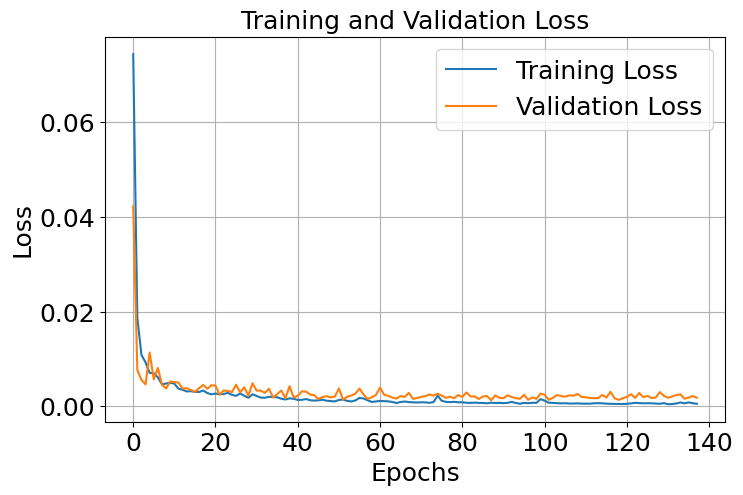

In [26]:
# CHUAN LOSS với font size 18
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs', fontsize=18)
plt.ylabel('Loss', fontsize=18)
plt.title('Training and Validation Loss', fontsize=18)
plt.legend(fontsize=18)
plt.grid(True)

# Tăng font của các chỉ số trục
plt.tick_params(axis='both', which='major', labelsize=18)

plt.show()

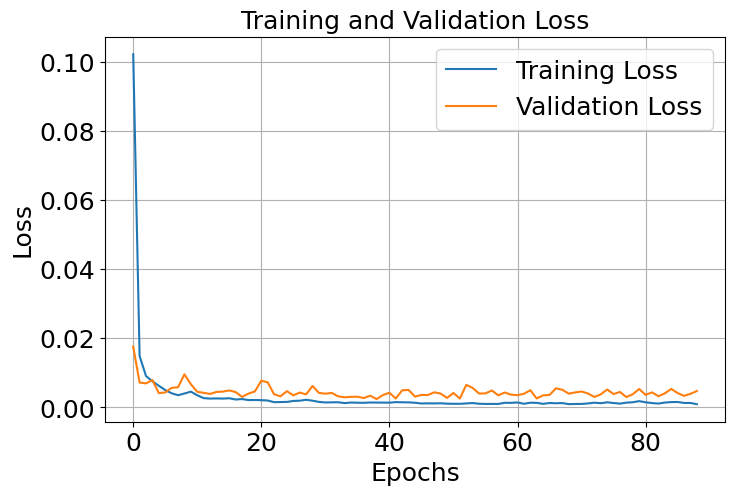

In [57]:
# CHUAN LOSS với font size 18
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs', fontsize=18)
plt.ylabel('Loss', fontsize=18)
plt.title('Training and Validation Loss', fontsize=18)
plt.legend(fontsize=18)
plt.grid(True)

# Tăng font của các chỉ số trục
plt.tick_params(axis='both', which='major', labelsize=18)

plt.show()

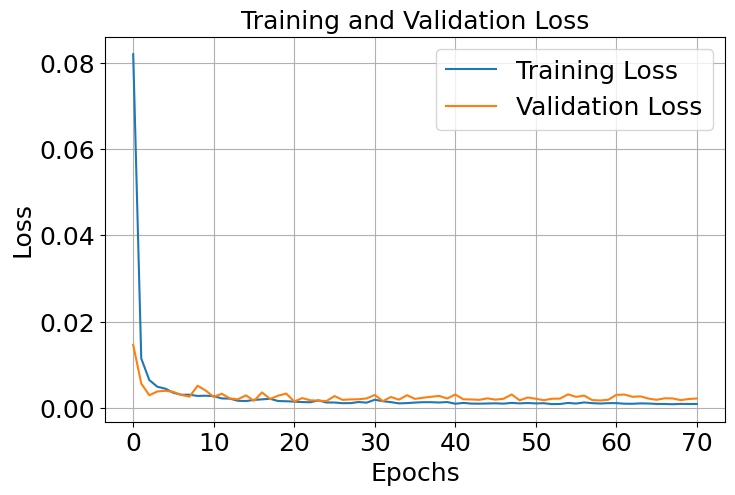

In [68]:
# CHUAN LOSS với font size 18
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs', fontsize=18)
plt.ylabel('Loss', fontsize=18)
plt.title('Training and Validation Loss', fontsize=18)
plt.legend(fontsize=18)
plt.grid(True)

# Tăng font của các chỉ số trục
plt.tick_params(axis='both', which='major', labelsize=18)

plt.show()

In [44]:
#---------CHIA PATCH--------
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# y_test_dict = {"Gas1_concentration": ..., "Gas2_concentration": ...}
# y_pred = model.predict(X_test_lstm) -> list: [Gas1_pred, Gas2_pred]

y_pred_gas1 = y_pred[0].flatten()  # CO
y_pred_gas2 = y_pred[1].flatten()  # C2H4

y_test_gas1 = y_test_dict['Gas1_concentration']
y_test_gas2 = y_test_dict['Gas2_concentration']

# ------------------- Output 1 -------------------
mae_1 = mean_absolute_error(y_test_gas1, y_pred_gas1)
mse_1 = mean_squared_error(y_test_gas1, y_pred_gas1)
rmse_1 = np.sqrt(mse_1)
nrmse_1 = rmse_1 / np.mean(y_test_gas1)
r2_1 = r2_score(y_test_gas1, y_pred_gas1)

# ------------------- Output 2 -------------------
mae_2 = mean_absolute_error(y_test_gas2, y_pred_gas2)
mse_2 = mean_squared_error(y_test_gas2, y_pred_gas2)
rmse_2 = np.sqrt(mse_2)
nrmse_2 = rmse_2 / np.mean(y_test_gas2)
r2_2 = r2_score(y_test_gas2, y_pred_gas2)

# ------------------- In kết quả -------------------
print(f"Output 1 - MAE: {mae_1:.4f}, MSE: {mse_1:.4f}, RMSE: {rmse_1:.4f}, NRMSE: {nrmse_1*100:.2f}%, R² Score: {r2_1:.4f}")
print(f"Output 2 - MAE: {mae_2:.4f}, MSE: {mse_2:.4f}, RMSE: {rmse_2:.4f}, NRMSE: {nrmse_2*100:.2f}%, R² Score: {r2_2:.4f}")

Output 1 - MAE: 0.0211, MSE: 0.0012, RMSE: 0.0344, NRMSE: 9.01%, R² Score: 0.9895
Output 2 - MAE: 0.0927, MSE: 0.0177, RMSE: 0.1330, NRMSE: 34.79%, R² Score: 0.8101


In [22]:
# Chuyển đổi dữ liệu test sang dạng 3D cho LSTM
X_test_lstm = np.reshape(X_test_encoded, (X_test_encoded.shape[0], 1, X_test_encoded.shape[1]))

# Dự đoán
y_pred = best_model.predict(X_test_lstm)

# Giải chuẩn hóa kết quả nếu cần
y_pred_renormalized = scaler.inverse_transform(y_pred)
y_test_renormalized = scaler.inverse_transform(y_test)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step


In [23]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Output 1
mae_1 = mean_absolute_error(y_test_renormalized[:, 0], y_pred_renormalized[:, 0])
mse_1 = mean_squared_error(y_test_renormalized[:, 0], y_pred_renormalized[:, 0])
rmse_1 = np.sqrt(mse_1)
mean_y1 = np.mean(y_test_renormalized[:, 0])
nrmse_1 = rmse_1 / mean_y1

# Output 2
mae_2 = mean_absolute_error(y_test_renormalized[:, 1], y_pred_renormalized[:, 1])
mse_2 = mean_squared_error(y_test_renormalized[:, 1], y_pred_renormalized[:, 1])
rmse_2 = np.sqrt(mse_2)
mean_y2 = np.mean(y_test_renormalized[:, 1])
nrmse_2 = rmse_2 / mean_y2

# R2 Scores
r2_1 = r2_score(y_test_renormalized[:, 0], y_pred_renormalized[:, 0])
r2_2 = r2_score(y_test_renormalized[:, 1], y_pred_renormalized[:, 1])

# In kết quả
# In kết quả
print(f"Output 1 - MAE: {mae_1:.4f}, MSE: {mse_1:.4f}, RMSE: {rmse_1:.4f}, NRMSE: {nrmse_1*100:.2f}%, R² Score: {r2_1:.4f}")
print(f"Output 2 - MAE: {mae_2:.4f}, MSE: {mse_2:.4f}, RMSE: {rmse_2:.4f}, NRMSE: {nrmse_2*100:.2f}%, R² Score: {r2_2:.4f}")

Output 1 - MAE: 13.2495, MSE: 382.1459, RMSE: 19.5486, NRMSE: 9.60%, R² Score: 0.9881
Output 2 - MAE: 0.5857, MSE: 0.5787, RMSE: 0.7607, NRMSE: 10.86%, R² Score: 0.9815


(5) Output 1 - MAE: 22.2989, MSE: 991.5013, RMSE: 31.4881, NRMSE: 17.75%, R² Score: 0.9657
Output 2 - MAE: 0.8981, MSE: 1.3281, RMSE: 1.1524, NRMSE: 14.99%, R² Score: 0.9589

Output 1 - MAE: 22.1455, MSE: 932.2493, RMSE: 30.5328, NRMSE: 17.21%, R² Score: 0.9678
Output 2 - MAE: 0.7058, MSE: 0.9320, RMSE: 0.9654, NRMSE: 12.56%, R² Score: 0.9711

Output 1 - MAE: 19.5707, MSE: 735.2325, RMSE: 27.1152, NRMSE: 15.28%, R² Score: 0.9746
Output 2 - MAE: 0.7802, MSE: 0.9558, RMSE: 0.9777, NRMSE: 12.72%, R² Score: 0.9704

Output 1 - MAE: 21.7897, MSE: 824.4204, RMSE: 28.7127, NRMSE: 16.18%, R² Score: 0.9715
Output 2 - MAE: 0.6849, MSE: 0.7807, RMSE: 0.8836, NRMSE: 11.49%, R² Score: 0.9758
4
Output 1 - MAE: 14.8323, MSE: 490.4104, RMSE: 22.1452, NRMSE: 12.48%, R² Score: 0.9830
Output 2 - MAE: 0.5659, MSE: 0.6299, RMSE: 0.7936, NRMSE: 10.32%, R² Score: 0.9805
Output 1 - MAE: 17.9353, MSE: 520.5215, RMSE: 22.8149, NRMSE: 11.21%, R² Score: 0.9837
Output 2 - MAE: 0.8834, MSE: 1.1322, RMSE: 1.0640, NRMSE: 15.18%, R² Score: 0.9638
Output 1 - MAE: 17.4546, MSE: 676.2869, RMSE: 26.0055, NRMSE: 12.78%, R² Score: 0.9789
Output 2 - MAE: 0.5151, MSE: 0.4419, RMSE: 0.6648, NRMSE: 9.49%, R² Score: 0.9859
Output 1 - MAE: 15.4434, MSE: 510.6249, RMSE: 22.5970, NRMSE: 11.10%, R² Score: 0.9841
Output 2 - MAE: 0.4154, MSE: 0.3327, RMSE: 0.5768, NRMSE: 8.23%, R² Score: 0.9894

Output 1 - MAE: 23.0914, MSE: 894.3229, RMSE: 29.9052, NRMSE: 14.69%, R² Score: 0.9721
Output 2 - MAE: 0.7024, MSE: 0.8366, RMSE: 0.9146, NRMSE: 13.05%, R² Score: 0.9733
1
Output 1 - MAE: 29.0217, MSE: 1520.9454, RMSE: 38.9993, NRMSE: 24.80%, R² Score: 0.9430
Output 2 - MAE: 0.9527, MSE: 2.9372, RMSE: 1.7138, NRMSE: 23.01%, R² Score: 0.8779
Output 1 - MAE: 23.5991, MSE: 1181.2945, RMSE: 34.3700, NRMSE: 21.85%, R² Score: 0.9557
Output 2 - MAE: 1.1383, MSE: 3.7719, RMSE: 1.9421, NRMSE: 26.07%, R² Score: 0.8432
Output 1 - MAE: 26.3397, MSE: 1445.8638, RMSE: 38.0245, NRMSE: 24.18%, R² Score: 0.9458
Output 2 - MAE: 0.9809, MSE: 3.1862, RMSE: 1.7850, NRMSE: 23.96%, R² Score: 0.8675
Output 1 - MAE: 16.8171, MSE: 757.2786, RMSE: 27.5187, NRMSE: 17.50%, R² Score: 0.9716
Output 2 - MAE: 0.8186, MSE: 2.7262, RMSE: 1.6511, NRMSE: 22.17%, R² Score: 0.8867

Output 1 - MAE: 19.6347, MSE: 720.2720, RMSE: 26.8379, NRMSE: 17.06%, R² Score: 0.9730
Output 2 - MAE: 1.0899, MSE: 3.3042, RMSE: 1.8178, NRMSE: 24.40%, R² Score: 0.8626

2
Output 1 - MAE: 19.8632, MSE: 618.7887, RMSE: 24.8755, NRMSE: 13.35%, R² Score: 0.9685
Output 2 - MAE: 0.8756, MSE: 1.4385, RMSE: 1.1994, NRMSE: 14.57%, R² Score: 0.9472

Output 1 - MAE: 17.2138, MSE: 496.2238, RMSE: 22.2761, NRMSE: 11.95%, R² Score: 0.9747
Output 2 - MAE: 0.9111, MSE: 2.1116, RMSE: 1.4531, NRMSE: 17.65%, R² Score: 0.9225

3
Output 1 - MAE: 20.3924, MSE: 738.9655, RMSE: 27.1839, NRMSE: 13.06%, R² Score: 0.9710
Output 2 - MAE: 1.0419, MSE: 1.4831, RMSE: 1.2178, NRMSE: 15.04%, R² Score: 0.9400

In [ ]:
# CNN cơ bản
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.models import Model

# Đầu vào ảnh 64x64x1
inputs = Input(shape=(64, 64, 1))

# Convolutional layers
x = Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
x = MaxPooling2D(pool_size=(2, 2))(x)

x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = MaxPooling2D(pool_size=(2, 2))(x)

x = Conv2D(128, (3, 3), activation='relu', padding='same')(x)
x = MaxPooling2D(pool_size=(2, 2))(x)

# Flatten và fully-connected layers
x = Flatten()(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)  # để tránh overfitting

# Nhánh đầu ra cho CO concentration
output1 = Dense(64, activation='relu')(x)
output1 = Dense(32, activation='relu')(output1)
output1 = Dense(1, activation='linear', name="Gas1_concentration")(output1)

# Nhánh đầu ra cho Ethylene concentration
output2 = Dense(64, activation='relu')(x)
output2 = Dense(32, activation='relu')(output2)
output2 = Dense(1, activation='linear', name="Gas2_concentration")(output2)

# Tạo mô hình CNN thường với 2 đầu ra
model = Model(inputs=inputs, outputs=[output1, output2])

# Compile mô hình
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss={'Gas1_concentration': 'mse', 'Gas2_concentration': 'mse'},
    metrics={'Gas1_concentration': 'mae', 'Gas2_concentration': 'mae'}
)

# Tóm tắt mô hình
model.summary()

In [7]:
# Đầu vào Resnet8
inputs = Input(shape=(64, 64, 1))

# Khối Convolutional (mô phỏng ResNet-8)
x = Conv2D(64, (3, 3), activation='relu')(inputs)
x = MaxPooling2D(pool_size=(3, 3))(x)
x = Conv2D(64, (3, 3), activation='relu')(x)
x = Conv2D(64, (3, 3), activation='relu')(x)
x = Conv2D(64, (3, 3), activation='relu')(x)
x = Conv2D(128, (3, 3), activation='relu')(x)
x = Conv2D(128, (3, 3), activation='relu')(x)
x = Conv2D(128, (3, 3), activation='relu')(x)
x = Flatten()(x)

# Nhánh đầu ra cho CO concentration
output1 = Dense(64, activation='relu')(x)
output1 = Dense(32, activation='relu')(output1)
output1 = Dense(1, activation='linear',name="Gas1_concentration")(output1)

# Nhánh đầu ra cho Ethylene concentration
output2 = Dense(64, activation='relu')(x)
output2 = Dense(32, activation='relu')(output2)
output2 = Dense(1, activation='linear',name="Gas2_concentration")(output2)

# Tạo mô hình với hai đầu ra
model = Model(inputs=inputs, outputs=[output1, output2])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss={'Gas1_concentration': 'mse', 'Gas2_concentration': 'mse'},
              metrics={'Gas1_concentration': 'mae', 'Gas2_concentration': 'mae'})

model.summary()

2025-11-25 14:00:30.090841: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 62, 62,    │        640 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 20, 20,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 18, 18,    │     36,928 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 16, 16,    │     36,928 │ conv2d_1[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 14, 14,    │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 12, 12,    │     73,856 │ conv2d_3[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 10, 10,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 8, 8, 128) │    147,584 │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 8192)      │          0 │ conv2d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │    524,352 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │    524,352 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,080 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │      2,080 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas1_concentration  │ (None, 1)         │         33 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas2_concentration  │ (None, 1)         │         33 │ dense_3[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,533,378 (5.85 MB)

 Trainable params: 1,533,378 (5.85 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Resnet 8 Early stopping
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping

# Đầu vào
inputs = Input(shape=(64, 64, 1))

# Khối CNN (mô phỏng ResNet-8)
x = Conv2D(64, (3, 3), activation='relu')(inputs)
x = MaxPooling2D(pool_size=(3, 3))(x)
x = Conv2D(64, (3, 3), activation='relu')(x)
x = Conv2D(64, (3, 3), activation='relu')(x)
x = Conv2D(64, (3, 3), activation='relu')(x)
x = Conv2D(128, (3, 3), activation='relu')(x)
x = Conv2D(128, (3, 3), activation='relu')(x)
x = Conv2D(128, (3, 3), activation='relu')(x)
x = Flatten()(x)

# Nhánh đầu ra CO
output1 = Dense(64, activation='relu')(x)
output1 = Dense(32, activation='relu')(output1)
output1 = Dense(1, activation='linear', name="Gas1_concentration")(output1)

# Nhánh đầu ra C2H4
output2 = Dense(64, activation='relu')(x)
output2 = Dense(32, activation='relu')(output2)
output2 = Dense(1, activation='linear', name="Gas2_concentration")(output2)

# Tạo mô hình
model = Model(inputs=inputs, outputs=[output1, output2])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss={'Gas1_concentration': 'mse', 'Gas2_concentration': 'mse'},
    metrics={'Gas1_concentration': 'mae', 'Gas2_concentration': 'mae'}
)

model.summary()

# ==== Early Stopping ====
early_stop = EarlyStopping(
    monitor='val_loss',      # theo dõi loss trên validation
    patience=10,             # dừng nếu 10 epoch không cải thiện
    restore_best_weights=True  # lấy lại trọng số tốt nhất
)


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 62, 62,    │        640 │ input_layer_1[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 20, 20,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 18, 18,    │     36,928 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 16, 16,    │     36,928 │ conv2d_8[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 14, 14,    │     36,928 │ conv2d_9[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 12, 12,    │     73,856 │ conv2d_10[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 10, 10,    │    147,584 │ conv2d_11[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 8, 8, 128) │    147,584 │ conv2d_12[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 8192)      │          0 │ conv2d_13[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │    524,352 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 64)        │    524,352 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 32)        │      2,080 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 32)        │      2,080 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas1_concentration  │ (None, 1)         │         33 │ dense_5[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas2_concentration  │ (None, 1)         │         33 │ dense_7[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,533,378 (5.85 MB)

 Trainable params: 1,533,378 (5.85 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
#RNN
import tensorflow as tf
from tensorflow.keras.layers import Input, Reshape, SimpleRNN, Dense, Dropout
from tensorflow.keras.models import Model

# Đầu vào ảnh 64x64x1 (coi như chuỗi 64 bước, mỗi bước 64 đặc trưng)
inputs = Input(shape=(64, 64, 1))  # (batch_size, time_steps, features, channels)

# Bỏ chiều kênh cuối cùng (1), reshape thành (batch_size, time_steps=64, features=64)
x = Reshape((64, 64))(inputs)  # (batch_size, time_steps, features)

# RNN layers (thay LSTM bằng SimpleRNN)
x = SimpleRNN(128, return_sequences=True, activation='tanh')(x)
x = SimpleRNN(64, activation='tanh')(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)

# Nhánh đầu ra cho CO concentration
output1 = Dense(64, activation='relu')(x)
output1 = Dense(32, activation='relu')(output1)
output1 = Dense(1, activation='linear', name="Gas1_concentration")(output1)

# Nhánh đầu ra cho Ethylene concentration
output2 = Dense(64, activation='relu')(x)
output2 = Dense(32, activation='relu')(output2)
output2 = Dense(1, activation='linear', name="Gas2_concentration")(output2)

# Tạo mô hình RNN hai đầu ra
model = Model(inputs=inputs, outputs=[output1, output2])

# Compile mô hình
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss={'Gas1_concentration': 'mse', 'Gas2_concentration': 'mse'},
    metrics={'Gas1_concentration': 'mae', 'Gas2_concentration': 'mae'}
)

# Hiển thị kiến trúc mô hình
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_2 (Reshape) │ (None, 64, 64)    │          0 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_2        │ (None, 64, 128)   │     24,704 │ reshape_2[0][0]   │
│ (SimpleRNN)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_3        │ (None, 64)        │     12,352 │ simple_rnn_2[0][… │
│ (SimpleRNN)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 128)       │      8,320 │ simple_rnn_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 64)        │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 64)        │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 32)        │      2,080 │ dense_11[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 32)        │      2,080 │ dense_13[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas1_concentration  │ (None, 1)         │         33 │ dense_12[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas2_concentration  │ (None, 1)         │         33 │ dense_14[0][0]    │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 66,114 (258.26 KB)

 Trainable params: 66,114 (258.26 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# LSTM trực tiếp không qua AE tuần tự từng dòng
import tensorflow as tf
from tensorflow.keras.layers import Input, Reshape, LSTM, Dense, Dropout
from tensorflow.keras.models import Model

# Đầu vào ảnh 64x64x1 (coi như chuỗi 64 bước, mỗi bước 64 đặc trưng)
inputs = Input(shape=(64, 64, 1))  # (batch_size, time_steps, features, channels)

# Bỏ chiều kênh cuối cùng (1), reshape thành (batch_size, time_steps=64, features=64)
x = Reshape((64, 64))(inputs)  # (batch_size, time_steps, features)

# RNN layers
x = LSTM(128, return_sequences=True)(x)   # LSTM đầu tiên
x = LSTM(64)(x)                            # LSTM thứ hai
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)

# Nhánh đầu ra cho CO concentration
output1 = Dense(64, activation='relu')(x)
output1 = Dense(32, activation='relu')(output1)
output1 = Dense(1, activation='linear', name="Gas1_concentration")(output1)

# Nhánh đầu ra cho Ethylene concentration
output2 = Dense(64, activation='relu')(x)
output2 = Dense(32, activation='relu')(output2)
output2 = Dense(1, activation='linear', name="Gas2_concentration")(output2)

# Tạo mô hình RNN hai đầu ra
model = Model(inputs=inputs, outputs=[output1, output2])

# Compile mô hình
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss={'Gas1_concentration': 'mse', 'Gas2_concentration': 'mse'},
    metrics={'Gas1_concentration': 'mae', 'Gas2_concentration': 'mae'}
)

# Hiển thị kiến trúc mô hình
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 64, 64)    │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 64, 128)   │     98,816 │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ (None, 64)        │     49,408 │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 128)       │      8,320 │ lstm_3[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 32)        │      2,080 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 32)        │      2,080 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas1_concentration  │ (None, 1)         │         33 │ dense_7[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas2_concentration  │ (None, 1)         │         33 │ dense_9[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 177,282 (692.51 KB)

 Trainable params: 177,282 (692.51 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# LSTM chia theo patch size 16 x 16
import tensorflow as tf
from tensorflow.keras.layers import Input, Reshape, Lambda, LSTM, Dense, Dropout
from tensorflow.keras.models import Model
import tensorflow.keras.backend as K

# Hàm chia patch 16x16
def extract_patches(x):
    # x shape: (batch, 64, 64, 1)
    patches = tf.image.extract_patches(
        images=x,
        sizes=[1, 16, 16, 1],
        strides=[1, 16, 16, 1],
        rates=[1, 1, 1, 1],
        padding='VALID'
    )
    # patches shape: (batch, 4, 4, 256)
    # Chuyển thành (batch, 16, 256)
    patches = tf.reshape(patches, (tf.shape(patches)[0], 16, 256))
    return patches

# Input ảnh
inputs = Input(shape=(64, 64, 1))

# Tách patch 16x16 → 16 patch, mỗi patch 256 pixels
x = Lambda(extract_patches)(inputs)

# LSTM xử lý sequence 16 bước, mỗi bước 256 feature
x = LSTM(128, return_sequences=True)(x)
x = LSTM(64)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.5)(x)

# Nhánh đầu ra CO
output1 = Dense(64, activation='relu')(x)
output1 = Dense(32, activation='relu')(output1)
output1 = Dense(1, activation='linear', name="Gas1_concentration")(output1)

# Nhánh đầu ra C2H4
output2 = Dense(64, activation='relu')(x)
output2 = Dense(32, activation='relu')(output2)
output2 = Dense(1, activation='linear', name="Gas2_concentration")(output2)

model = Model(inputs, [output1, output2])

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss={'Gas1_concentration': 'mse', 'Gas2_concentration': 'mse'},
    metrics={'Gas1_concentration': 'mae', 'Gas2_concentration': 'mae'}
)

model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_2 (Lambda)   │ (None, 16, 256)   │          0 │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_8 (LSTM)       │ (None, 16, 128)   │    197,120 │ lambda_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_9 (LSTM)       │ (None, 64)        │     49,408 │ lstm_8[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_20 (Dense)    │ (None, 128)       │      8,320 │ lstm_9[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 128)       │          0 │ dense_20[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_21 (Dense)    │ (None, 64)        │      8,256 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_23 (Dense)    │ (None, 64)        │      8,256 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_22 (Dense)    │ (None, 32)        │      2,080 │ dense_21[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_24 (Dense)    │ (None, 32)        │      2,080 │ dense_23[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas1_concentration  │ (None, 1)         │         33 │ dense_22[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Gas2_concentration  │ (None, 1)         │         33 │ dense_24[0][0]    │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 275,586 (1.05 MB)

 Trainable params: 275,586 (1.05 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
# Huấn luyện mô hình với hai đầu ra
history = model.fit(
    X_train, 
    {'Gas1_concentration': y_train[:, 0], 'Gas2_concentration': y_train[:, 1]},
    epochs= 100, 
    batch_size=32, 
    validation_data=(X_test, {'Gas1_concentration': y_test[:, 0], 'Gas2_concentration': y_test[:, 1]})
)


Epoch 1/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 22s 239ms/step - Gas1_concentration_loss: 3.3628 - Gas1_concentration_mae: 1.3225 - Gas2_concentration_loss: 5.5510 - Gas2_concentration_mae: 1.2598 - loss: 8.9162 - val_Gas1_concentration_loss: 0.3396 - val_Gas1_concentration_mae: 0.5166 - val_Gas2_concentration_loss: 0.0958 - val_Gas2_concentration_mae: 0.2287 - val_loss: 0.4299
Epoch 2/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 6s 199ms/step - Gas1_concentration_loss: 0.1472 - Gas1_concentration_mae: 0.3123 - Gas2_concentration_loss: 0.0990 - Gas2_concentration_mae: 0.2538 - loss: 0.2462 - val_Gas1_concentration_loss: 0.0969 - val_Gas1_concentration_mae: 0.2761 - val_Gas2_concentration_loss: 0.1816 - val_Gas2_concentration_mae: 0.3475 - val_loss: 0.2735
Epoch 3/100
31/31 ━━━━━━━━━━━━━━━━━━━━ 6s 199ms/step - Gas1_concentration_loss: 0.1113 - Gas1_concentration_mae: 0.2817 - Gas2_concentration_loss: 0.1193 - Gas2_concentration_mae: 0.2803 - loss: 0.2306 - val_Gas1_concentration_loss: 0.0967 - val_Gas1_concen

In [24]:
from sklearn.metrics import mean_absolute_error, r2_score

# Dự đoán trên tập kiểm tra
y_pred = model.predict(X_test)

# Tách dự đoán cho từng khí
y_pred_gas1 = y_pred[0] # Dự đoán nồng độ khí 1
y_pred_gas2 = y_pred[1] # Dự đoán nồng độ khí 2


8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 166ms/step


In [25]:
# Inverse transform cho giá trị ground truth và dự đoán
# Ghép lại dự đoán thành mảng 2 chiều để inverse transform
y_pred_combined = np.column_stack((y_pred_gas1, y_pred_gas2))

# Inverse transform cho ground truth và dự đoán
y_true_rescaled = scaler.inverse_transform(y_test)  # Ground truth
y_pred_rescaled = scaler.inverse_transform(y_pred_combined)  # Dự đoán đã ghép

# Tách lại sau khi rescale để dùng cho các bước tiếp theo (nếu cần)
y_pred_gas1_rescaled = y_pred_rescaled[:, 0]
y_pred_gas2_rescaled = y_pred_rescaled[:, 1]
y_true_gas1_rescaled = y_true_rescaled[:, 0]
y_true_gas2_rescaled = y_true_rescaled[:, 1]

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# CO gas
mae_1 = mean_absolute_error(y_true_gas1_rescaled, y_pred_gas1_rescaled)
mse_1 = mean_squared_error(y_true_gas1_rescaled, y_pred_gas1_rescaled)
rmse_1 = np.sqrt(mse_1)
nrmse_1 = rmse_1 / (np.max(y_true_gas1_rescaled) - np.min(y_true_gas1_rescaled))
r2_1 = r2_score(y_true_gas1_rescaled, y_pred_gas1_rescaled)

# Ethylene gas
mae_2 = mean_absolute_error(y_true_gas2_rescaled, y_pred_gas2_rescaled)
mse_2 = mean_squared_error(y_true_gas2_rescaled, y_pred_gas2_rescaled)
rmse_2 = np.sqrt(mse_2)
nrmse_2 = rmse_2 / (np.max(y_true_gas2_rescaled) - np.min(y_true_gas2_rescaled))
r2_2 = r2_score(y_true_gas2_rescaled, y_pred_gas2_rescaled)

# In kết quả
print(f"CO gas       - MAE: {mae_1:.4f}, MSE: {mse_1:.4f}, RMSE: {rmse_1:.4f}, NRMSE: {nrmse_1*100:.2f}%, R² Score: {r2_1:.4f}")
print(f"Ethylene gas - MAE: {mae_2:.4f}, MSE: {mse_2:.4f}, RMSE: {rmse_2:.4f}, NRMSE: {nrmse_2*100:.2f}%, R² Score: {r2_2:.4f}")

CO gas       - MAE: 18.5196, MSE: 777.0366, RMSE: 27.8754, NRMSE: 5.23%, R² Score: 0.9709
Ethylene gas - MAE: 0.8768, MSE: 2.5767, RMSE: 1.6052, NRMSE: 9.63%, R² Score: 0.8929


Resnet: (1)
CO gas       - MAE: 23.7872, MSE: 1408.3574, RMSE: 37.5281, NRMSE: 7.04%, R² Score: 0.9472
Ethylene gas - MAE: 0.9721, MSE: 2.9282, RMSE: 1.7112, NRMSE: 10.27%, R² Score: 0.8783



CNN:
CO gas       - MAE: 46.2468, MSE: 5296.3782, RMSE: 72.7762, NRMSE: 13.65%, R² Score: 0.8346
Ethylene gas - MAE: 2.1780, MSE: 9.2690, RMSE: 3.0445, NRMSE: 16.61%, R² Score: 0.7038
Resnet
CO gas       - MAE: 14.9502, MSE: 570.7511, RMSE: 23.8904, NRMSE: 4.48%, R² Score: 0.9822
Ethylene gas - MAE: 0.6617, MSE: 0.8495, RMSE: 0.9217, NRMSE: 5.03%, R² Score: 0.9729
RNN
CO gas       - MAE: 23.6308, MSE: 1291.1493, RMSE: 35.9326, NRMSE: 6.74%, R² Score: 0.9597
Ethylene gas - MAE: 1.5184, MSE: 4.9149, RMSE: 2.2169, NRMSE: 12.09%, R² Score: 0.8429
LSTM từng dòng cho vào
CO gas       - MAE: 19.9426, MSE: 1186.1698, RMSE: 34.4408, NRMSE: 6.46%, R² Score: 0.9630
Ethylene gas - MAE: 1.5593, MSE: 5.5438, RMSE: 2.3545, NRMSE: 12.85%, R² Score: 0.8228
------LSTM CHIA THANH PATCH 16X16
CO gas       - MAE: 11.2317, MSE: 336.2822, RMSE: 18.3380, NRMSE: 3.44%, R² Score: 0.9895
Ethylene gas - MAE: 1.6995, MSE: 5.9429, RMSE: 2.4378, NRMSE: 13.30%, R² Score: 0.8101


In [22]:
# TRANSFORMER 
import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping

# =========================
# PATCH EMBEDDING
# =========================
def patch_embedding(inputs, patch_size=8, embed_dim=64):
    # Chia ảnh 64×64 thành 8×8 patch = 64 patch
    x = Conv2D(embed_dim,
               kernel_size=patch_size,
               strides=patch_size,
               padding="valid")(inputs)
    # output shape: (batch, 8, 8, 64) → reshape thành (batch, 64, 64)
    x = Reshape((64, embed_dim))(x)
    return x

# =========================
# TRANSFORMER ENCODER BLOCK
# =========================
def transformer_encoder(x, num_heads=4, ff_dim=128, dropout=0.1):
    # Multi-head Self-Attention
    attn = MultiHeadAttention(num_heads=num_heads, key_dim=x.shape[-1])(x, x)
    attn = Dropout(dropout)(attn)
    x = Add()([x, attn])
    x = LayerNormalization(epsilon=1e-6)(x)

    # Feed Forward Network
    ff = Dense(ff_dim, activation="relu")(x)
    ff = Dense(x.shape[-1])(ff)
    ff = Dropout(dropout)(ff)
    x = Add()([x, ff])
    x = LayerNormalization(epsilon=1e-6)(x)
    return x

# =========================
# INPUT
# =========================
inputs = Input(shape=(64, 64, 1))

# Patch Embedding
x = patch_embedding(inputs, patch_size=8, embed_dim=64)

# Transformer Blocks
for _ in range(4):     # số lượng encoder block
    x = transformer_encoder(x, num_heads=4, ff_dim=128)

# Flatten trước khi đưa vào Dense
x = Flatten()(x)

# =========================
# Output head 1 — CO concentration
# =========================
output1 = Dense(128, activation='relu')(x)
output1 = Dense(64, activation='relu')(output1)
output1 = Dense(1, activation='linear', name="Gas1_concentration")(output1)

# =========================
# Output head 2 — C₂H₄ concentration
# =========================
output2 = Dense(128, activation='relu')(x)
output2 = Dense(64, activation='relu')(output2)
output2 = Dense(1, activation='linear', name="Gas2_concentration")(output2)

# =========================
# MODEL
# =========================
model = Model(inputs=inputs, outputs=[output1, output2])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss={
        "Gas1_concentration": "mse",
        "Gas2_concentration": "mse"
    },
    metrics={
        "Gas1_concentration": "mae",
        "Gas2_concentration": "mae"
    }
)

model.summary()

# =========================
# EARLY STOPPING
# =========================
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=12,
    restore_best_weights=True,
    mode='min'
)

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 8, 8, 64)  │      4,160 │ input_layer_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 64, 64)    │          0 │ conv2d_17[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     66,368 │ reshape_1[0][0],  │
│ (MultiHeadAttentio… │                   │            │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64, 64)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64)    │          0 │ reshape_1[0][0],  │
│                     │                   │            │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 64, 64)    │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 64, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 64, 64)    │      8,256 │ dense_12[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64, 64)    │          0 │ dense_13[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 64, 64)    │     66,368 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 64, 64)    │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64, 64)    │        128 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 64, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 64, 64)    │      8,256 │ dense_14[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 64, 64)    │          0 │ dense_15[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 64, 64)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_7[0][0] 

 Total params: 1,402,434 (5.35 MB)

 Trainable params: 1,402,434 (5.35 MB)

 Non-trainable params: 0 (0.00 B)

# AE_LSTM  (1)
Output 1 - MAE: 17.5571, MSE: 772.3772, RMSE: 27.7917, NRMSE: 17.67%, R² Score: 0.9711
Output 2 - MAE: 0.7833, MSE: 2.2191, RMSE: 1.4897, NRMSE: 20.00%, R² Score: 0.9077
RESnet8:
CO gas       - MAE: 23.7872, MSE: 1408.3574, RMSE: 37.5281, NRMSE: 7.04%, R² Score: 0.9472
Ethylene gas - MAE: 0.9721, MSE: 2.9282, RMSE: 1.7112, NRMSE: 10.27%, R² Score: 0.8783
# Transformer
CO gas       - MAE: 18.5196, MSE: 777.0366, RMSE: 27.8754, NRMSE: 5.23%, R² Score: 0.9709
Ethylene gas - MAE: 0.8768, MSE: 2.5767, RMSE: 1.6052, NRMSE: 9.63%, R² Score: 0.8929